<a href="https://colab.research.google.com/github/ChiraniSiriwardhana/SL-DenguePrediction-dashboard/blob/main/notebooks/Sri_Lanka_Dengue_Ensemble_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


## **Comparative Analysis of Ensemble Learning and Hybrid Models for Dengue Case Prediction in Sri Lanka**

**Student Name:**  Siriwardhana C.R.H.P.E.R.


**Index Number:** 224229M



## 1. Introduction
Dengue is a major public health concern in Sri Lanka, and outbreaks are strongly influenced by weather conditions such as rainfall and temperature. Accurate short-term forecasts can help health authorities plan vector control and resource allocation in advance.

This notebook builds and compares machine learning models that predict **next week's dengue cases** for each district of Sri Lanka, and presents the results in an interactive dashboard.

The study aims to investigate how different ensemble learning techniques and hybrid forecasting approaches perform in dengue case prediction.


## 2. Objectives
1. Analyse historical dengue trends and their relationship with weather.
2. Compare **Bagging** (Random Forest) and **Boosting** (XGBoost) on a Sri Lankan dataset.
3. Build a **Stacking** ensemble of Random Forest, XGBoost, LightGBM and CatBoost, and compare two ways of combining them: a Ridge meta-learner and a convex-weight average.
4. Build a **Hybrid ARIMA + Random Forest** model and show how the two are combined.
5. Evaluate all models, identify the best model and explain why it performs best.
6. Deploy the results as an interactive dashboard for district-level forecasting.

## 3. Models to be Evaluated

- **Baseline:** Naive Forecast
- **Bagging:** Random Forest
- **Boosting:** XGBoost, LightGBM, CatBoost
- **Stacking:** Stacking Ensemble
- **Time Series:** ARIMA
- **Hybrid:** ARIMA + Random Forest

## 4. Dataset
- **Source:** Sri Lanka weekly dengue cases and weather dataset, 2007–2024 (25 districts).[View source on GitHub](https://github.com/rajaththomson/sri-lanka-dengue-fever-analysis/blob/master/Updated_Sri_lanka_dengue_cases_weather_weekly_2007_2024_.csv)
- **Size:** 22,900 weekly records, 19 columns.
- **Target:** `Number_of_Cases` of the following week.
- **Predictors:** past cases, past rainfall and temperature (lagged), seasonal features and district.

[View Dataset on GitHub](https://github.com/ChiraniSiriwardhana/SL-DenguePrediction-dashboard/tree/main/data)

##5. Project Repository

[GitHub Repository – SL-DenguePrediction-dashboard](https://github.com/ChiraniSiriwardhana/SL-DenguePrediction-dashboard)


---
**Tools & Technologies:** Python | Google Colab | Pandas | Scikit-learn | XGBoost | LightGBM | CatBoost | Statsmodels | SHAP


## 1. Installation of Required Libraries

In [ ]:

# Install required libraries

!pip install -q xgboost lightgbm catboost shap statsmodels

print("Libraries installed successfully!")


Libraries installed successfully!


## 2. Importing Required Libraries

In [ ]:


# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning models
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.linear_model import Ridge
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

# Model evaluation
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Time series forecasting
from statsmodels.tsa.arima.model import ARIMA

# Model explainability
import shap

# Settings
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
pd.set_option("display.max_columns", None)

print("All libraries imported successfully!")



All libraries imported successfully!


## 3. Dataset Loading

In [ ]:

# GitHub Raw CSV URL
DATA_URL = "https://raw.githubusercontent.com/ChiraniSiriwardhana/SL-DenguePrediction-dashboard/refs/heads/main/data/Sri_Lanka_Dengue_Dataset.csv"

# Load dataset
df = pd.read_csv(DATA_URL)

# Convert date columns into datetime format
df['Week_Start_Date'] = pd.to_datetime(
    df['Week_Start_Date'], format='%m/%d/%Y'
)

df['Week_End_Date'] = pd.to_datetime(
    df['Week_End_Date'], format='%m/%d/%Y'
)

# Sort records by district and date
df = df.sort_values(
    ['District', 'Week_Start_Date']
).reset_index(drop=True)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)
print("Date columns converted successfully!")

# Display first five rows
display(df.head())


Dataset loaded successfully!
Dataset Shape: (22900, 19)
Date columns converted successfully!


,District,Number_of_Cases,Week_Start_Date,Month,Year,Week,Week_End_Date,Avg Max Temp (°C),Avg Min Temp (°C),Avg Apparent Max Temp (°C),Avg Apparent Min Temp (°C),Total Precipitation (mm),Total Rain (mm),Avg Wind Speed (km/h),Max Wind Gusts (km/h),Weather Code,Avg Daylight Duration (hours),Avg Sunrise Time,Avg Sunset Time
0,Ampara,0,2007-01-01,1,2007,1,2007-01-08,26.9375,21.8625,28.8500,24.1000,8.0,8.0,18.2000,44.3,3,11.714583,376,1079
1,Ampara,0,2007-01-08,1,2007,2,2007-01-15,26.3500,23.3250,30.2625,26.7000,86.1,86.1,17.0250,43.6,53,11.733333,378,1082
2,Ampara,0,2007-01-15,1,2007,3,2007-01-22,27.2125,23.1625,29.5750,25.9625,3.1,3.1,20.1875,48.2,51,11.754167,380,1085
3,Ampara,0,2007-01-22,1,2007,4,2007-01-29,26.7250,23.0375,29.9500,26.1125,53.6,53.6,17.2000,42.5,61,11.783333,381,1088
4,Ampara,0,2007-01-29,1,2007,5,2007-02-05,27.3625,22.9625,30.7500,26.1250,8.2,8.2,17.2625,40.0,51,11.812500,382,1090


## 4. Dataset Understanding

In [ ]:

# Display dataset dimensions
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

# Display column names
print("\nDataset Columns:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset Information:")
df.info()

# Display statistical summary
print("\nStatistical Summary:")
display(df.describe(include='all').T)


Number of Rows: 22900
Number of Columns: 19

Dataset Columns:
['District', 'Number_of_Cases', 'Week_Start_Date', 'Month', 'Year', 'Week', 'Week_End_Date', 'Avg Max Temp (°C)', 'Avg Min Temp (°C)', 'Avg Apparent Max Temp (°C)', 'Avg Apparent Min Temp (°C)', 'Total Precipitation (mm)', 'Total Rain (mm)', 'Avg Wind Speed (km/h)', 'Max Wind Gusts (km/h)', 'Weather Code', 'Avg Daylight Duration (hours)', 'Avg Sunrise Time', 'Avg Sunset Time']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22900 entries, 0 to 22899
Data columns (total 19 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   District                       22900 non-null  object        
 1   Number_of_Cases                22900 non-null  int64         
 2   Week_Start_Date                22900 non-null  datetime64[ns]
 3   Month                          22900 non-null  int64         
 4   Year                

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
District,22900,25,Ampara,916,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Number_of_Cases,22900.0,NaN,NaN,NaN,34.739607,0.0,2.0,9.0,31.0,2631.0,87.523903
Week_Start_Date,22900,NaN,NaN,NaN,2015-10-08 12:00:00,2007-01-01 00:00:00,2011-05-21 06:00:00,2015-10-08 12:00:00,2020-02-25 18:00:00,2024-07-15 00:00:00,NaN
Month,22900.0,NaN,NaN,NaN,6.437773,1.0,3.0,6.0,9.0,12.0,3.444179
Year,22900.0,NaN,NaN,NaN,2015.276201,2007.0,2011.0,2015.0,2020.0,2024.0,5.073494
Week,22900.0,NaN,NaN,NaN,26.222707,1.0,13.0,26.0,39.0,53.0,15.033863
Week_End_Date,22900,NaN,NaN,NaN,2015-10-15 12:00:00,2007-01-08 00:00:00,2011-05-28 06:00:00,2015-10-15 12:00:00,2020-03-03 18:00:00,2024-07-22 00:00:00,NaN
Avg Max Temp (°C),22900.0,NaN,NaN,NaN,29.604291,15.6,28.15,29.425,31.4125,38.6125,3.029898
Avg Min Temp (°C),22900.0,NaN,NaN,NaN,23.525223,7.2125,22.45,24.025,25.2875,29.2625,2.765298
Avg Apparent Max Temp (°C),22900.0,NaN,NaN,NaN,33.941691,13.4875,32.3,34.125,36.2875,44.3375,3.733032


## 5. Data Quality Checking

This section checks the dataset for missing values, duplicate records, and duplicate district-week observations to ensure data quality before further preprocessing and model development.

In [ ]:

# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check total missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Check duplicate district-week records
print(
    "Duplicate District-Week Records:",
    df.duplicated(subset=['District', 'Week_Start_Date']).sum()
)

# Check number of unique districts
print("\nNumber of Districts:", df['District'].nunique())

# Check date range
print("Date Range:", df['Week_Start_Date'].min(), "to", df['Week_Start_Date'].max())


# 1. Check weekly intervals
gaps = df.groupby("District")["Week_Start_Date"].diff().dropna().dt.days.unique()
print("\nWeek gaps (days):", gaps)

# 2. Check whether rainfall columns are identical
print(
    "Rain columns identical:",
    (df["Total Precipitation (mm)"] == df["Total Rain (mm)"]).all()
)

# 3. Check number of weeks per district
print(
    "Weeks per district (unique):",
    df.groupby("District").size().unique()
)

# 4. Check percentage of zero-case weeks
zero_share = (df["Number_of_Cases"] == 0).mean()
print("Share of zero-case weeks: {:.1%}".format(zero_share))


Missing Values:
District                         0
Number_of_Cases                  0
Week_Start_Date                  0
Month                            0
Year                             0
Week                             0
Week_End_Date                    0
Avg Max Temp (°C)                0
Avg Min Temp (°C)                0
Avg Apparent Max Temp (°C)       0
Avg Apparent Min Temp (°C)       0
Total Precipitation (mm)         0
Total Rain (mm)                  0
Avg Wind Speed (km/h)            0
Max Wind Gusts (km/h)            0
Weather Code                     0
Avg Daylight Duration (hours)    0
Avg Sunrise Time                 0
Avg Sunset Time                  0
dtype: int64

Total Missing Values: 0

Duplicate Rows: 0
Duplicate District-Week Records: 0

Number of Districts: 25
Date Range: 2007-01-01 00:00:00 to 2024-07-15 00:00:00

Week gaps (days): [7]
Rain columns identical: True
Weeks per district (unique): [916]
Share of zero-case weeks: 13.0%



### Data Quality Findings

The `Total Precipitation (mm)` and `Total Rain (mm)` features contain identical values. Therefore, one of these redundant features will be removed during data preprocessing.

Approximately 13% of district-week observations report zero dengue cases. This indicates that the target variable contains a considerable proportion of zero values. Therefore, MAE, RMSE, and R² are selected as the primary evaluation metrics instead of percentage-based metrics such as MAPE, which can be problematic when actual values are zero.


## 6. Data Preprocessing

In [ ]:
# Remove redundant rainfall column
df = df.drop(columns=["Total Rain (mm)"])

# Remove sunrise and sunset time columns
df = df.drop(columns=["Avg Sunrise Time", "Avg Sunset Time"])

print("Preprocessing completed successfully!")
print("Updated Dataset Shape:", df.shape)

print("\nRemaining Columns:")
print(df.columns.tolist())

Preprocessing completed successfully!
Updated Dataset Shape: (22900, 16)

Remaining Columns:
['District', 'Number_of_Cases', 'Week_Start_Date', 'Month', 'Year', 'Week', 'Week_End_Date', 'Avg Max Temp (°C)', 'Avg Min Temp (°C)', 'Avg Apparent Max Temp (°C)', 'Avg Apparent Min Temp (°C)', 'Total Precipitation (mm)', 'Avg Wind Speed (km/h)', 'Max Wind Gusts (km/h)', 'Weather Code', 'Avg Daylight Duration (hours)']


## 7. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the distribution, trends, patterns, and relationships within the dengue and weather dataset. Visualizations are used to identify important characteristics of the data before developing machine learning models.


### 7.1 Target Variable Distribution

This section analyzes the distribution of weekly dengue cases to understand the frequency of low and high case counts and identify potential outliers.
- Histogram of Weekly Dengue Cases
- Boxplot of Weekly Dengue Cases

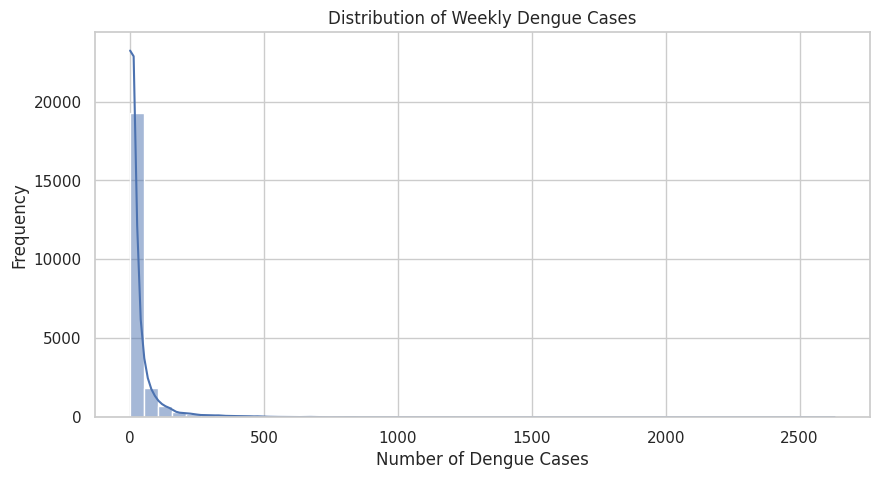

In [ ]:
# Plot the distribution of dengue cases
plt.figure(figsize=(10, 5))

sns.histplot(
    df["Number_of_Cases"],
    bins=50,
    kde=True
)

plt.title("Distribution of Weekly Dengue Cases")
plt.xlabel("Number of Dengue Cases")
plt.ylabel("Frequency")
plt.show()

**Distribution Analysis:** The target variable, `Number_of_Cases`, exhibits a highly right-skewed distribution. Most district-week observations contain relatively low dengue case counts, while a smaller number of observations have considerably higher values. This indicates the presence of extreme dengue case values that may represent outbreak periods. Further analysis is required to investigate these potential outliers.

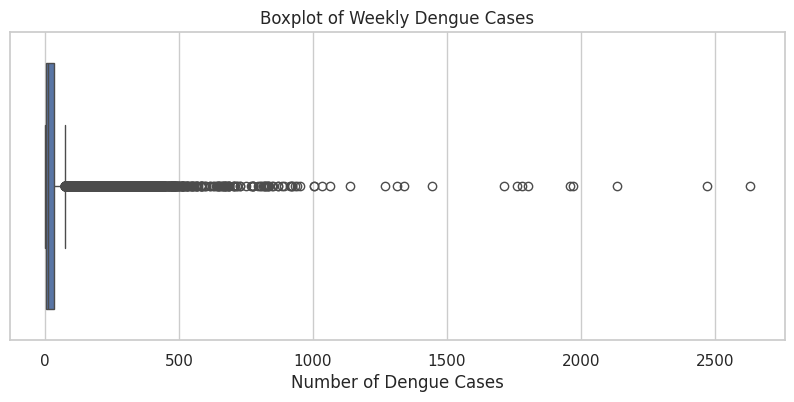

In [ ]:
# Boxplot of weekly dengue cases
plt.figure(figsize=(10, 4))

sns.boxplot(x=df["Number_of_Cases"])

plt.title("Boxplot of Weekly Dengue Cases")
plt.xlabel("Number of Dengue Cases")
plt.show()

**Boxplot Analysis:** The boxplot reveals a highly right-skewed distribution with numerous observations beyond the upper whisker. These observations represent potential extreme values in weekly dengue cases, which may correspond to periods of increased dengue transmission. Therefore, these values should be investigated rather than automatically removed, as they may contain important information about dengue outbreaks.

### 7.2 Weekly Dengue Cases Trend

This section analyzes the changes in weekly dengue cases over time to identify long-term trends, fluctuations, and potential outbreak periods.

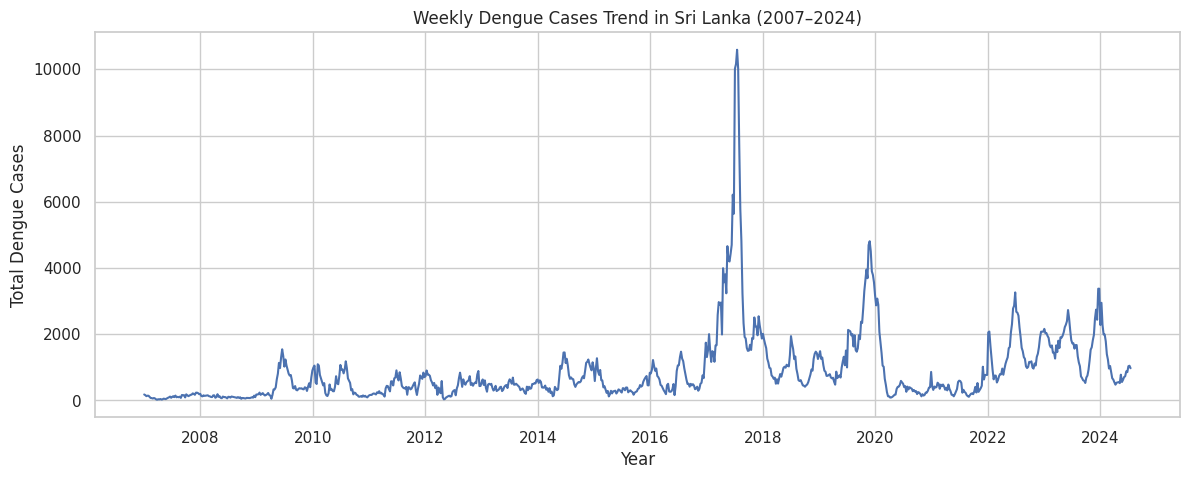

In [ ]:
# Calculate total weekly dengue cases across all districts
weekly_cases = df.groupby("Week_Start_Date")["Number_of_Cases"].sum()

# Plot weekly dengue cases trend
plt.figure(figsize=(14, 5))

plt.plot(weekly_cases.index, weekly_cases.values)

plt.title("Weekly Dengue Cases Trend in Sri Lanka (2007–2024)")
plt.xlabel("Year")
plt.ylabel("Total Dengue Cases")
plt.grid(True)

plt.show()

**Weekly Trend Analysis:** The weekly dengue case trend reveals considerable fluctuations over the study period. A significant outbreak peak is observed in 2017, with weekly cases exceeding 10,000. Other notable increases are observed during 2019–2020 and 2022–2024. These fluctuations indicate that dengue transmission varies over time, with distinct outbreak periods. Therefore, capturing temporal patterns is important for developing reliable dengue prediction models.

### 7.3 District-wise Dengue Case Distribution

This section compares the total reported dengue cases across the 25 districts to identify districts with relatively higher and lower dengue case burdens.

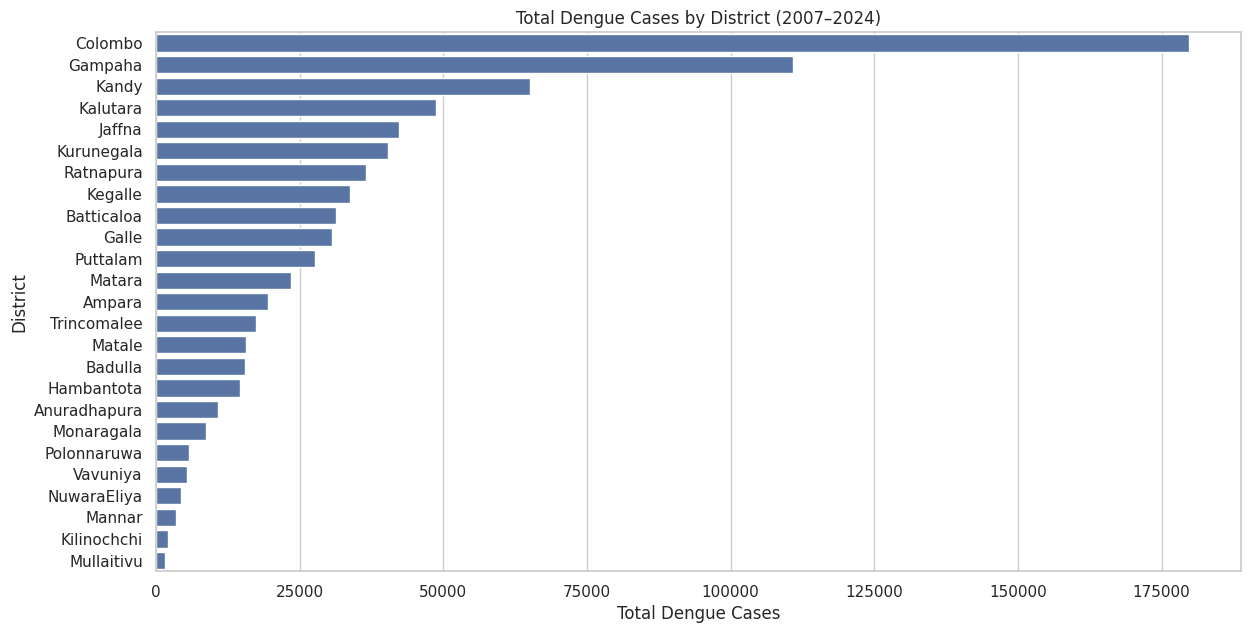

In [ ]:
# Calculate total dengue cases for each district
district_cases = (
    df.groupby("District")["Number_of_Cases"]
    .sum()
    .sort_values(ascending=False)
)

# Plot district-wise dengue cases
plt.figure(figsize=(14, 7))

sns.barplot(
    x=district_cases.values,
    y=district_cases.index
)

plt.title("Total Dengue Cases by District (2007–2024)")
plt.xlabel("Total Dengue Cases")
plt.ylabel("District")
plt.show()

**District-wise Analysis:** The district-wise analysis reveals considerable geographical variation in dengue cases across Sri Lanka. Colombo records the highest cumulative number of dengue cases, followed by Gampaha and Kandy. In contrast, Mullaitivu and Kilinochchi report relatively lower case counts. These findings highlight the importance of considering district-level differences when developing dengue prediction models.

### 7.4 Monthly Seasonal Patterns

This section examines the average monthly distribution of dengue cases to identify recurring seasonal patterns and periods with relatively higher dengue transmission.

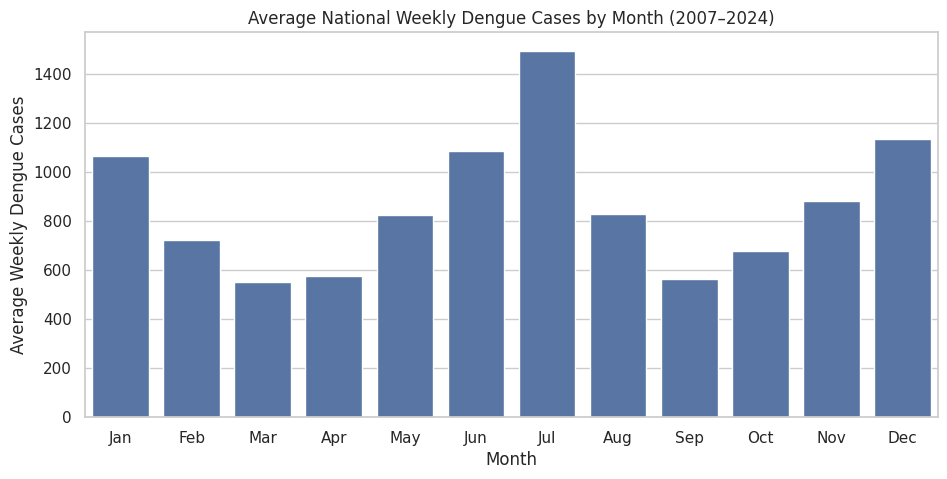

In [ ]:
# Calculate total weekly dengue cases across all districts
weekly_national = (
    df.groupby(["Week_Start_Date", "Month"])["Number_of_Cases"]
    .sum()
    .reset_index()
)

# Calculate average national weekly cases for each month
monthly_cases = (
    weekly_national.groupby("Month")["Number_of_Cases"]
    .mean()
)

# Plot monthly seasonal pattern
plt.figure(figsize=(11, 5))

sns.barplot(
    x=monthly_cases.index,
    y=monthly_cases.values
)

plt.title("Average National Weekly Dengue Cases by Month (2007–2024)")
plt.xlabel("Month")
plt.ylabel("Average Weekly Dengue Cases")

plt.xticks(
    range(12),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.show()

**Monthly Seasonal Analysis:** The monthly analysis reveals variations in average national weekly dengue cases throughout the year. July records the highest average weekly case count, followed by December and June. In contrast, March and April show relatively lower case counts. These findings suggest the presence of seasonal variations in dengue transmission, highlighting the importance of including temporal features in dengue prediction models.

### 7.5 Weather Feature Analysis

This section investigates the relationships between weather conditions and dengue cases. Scatter plots are used to explore how changes in temperature, rainfall, and wind conditions are associated with weekly dengue case counts.

7.5.1 Rainfall vs Dengue Cases – Interpretation

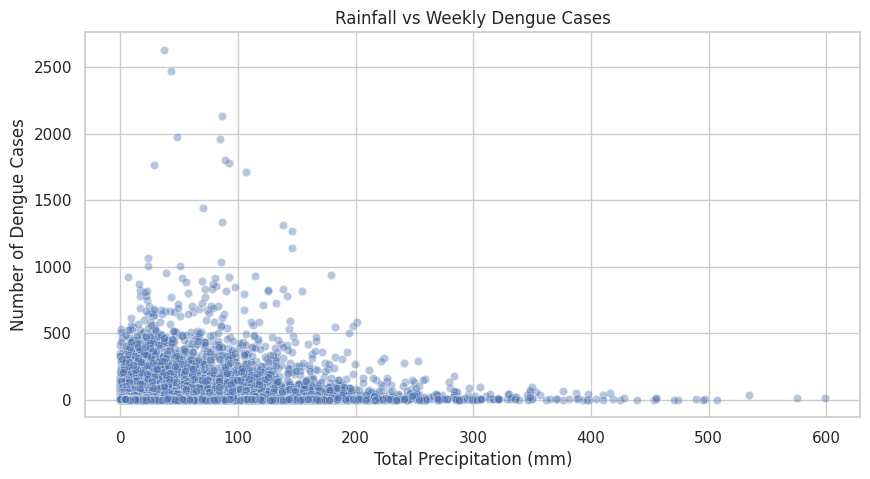

In [ ]:
# Relationship between rainfall and dengue cases
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x="Total Precipitation (mm)",
    y="Number_of_Cases",
    alpha=0.4
)

plt.title("Rainfall vs Weekly Dengue Cases")
plt.xlabel("Total Precipitation (mm)")
plt.ylabel("Number of Dengue Cases")
plt.show()

**Rainfall Analysis:** The scatter plot shows no clear linear relationship between rainfall and weekly dengue cases. Higher dengue case counts are mainly observed under low to moderate rainfall conditions, while observations with very high rainfall generally show lower case counts. However, considerable variability exists across rainfall levels, suggesting that rainfall alone may not sufficiently explain dengue case variations.

7.5.2 Maximum Temperature vs Dengue Cases

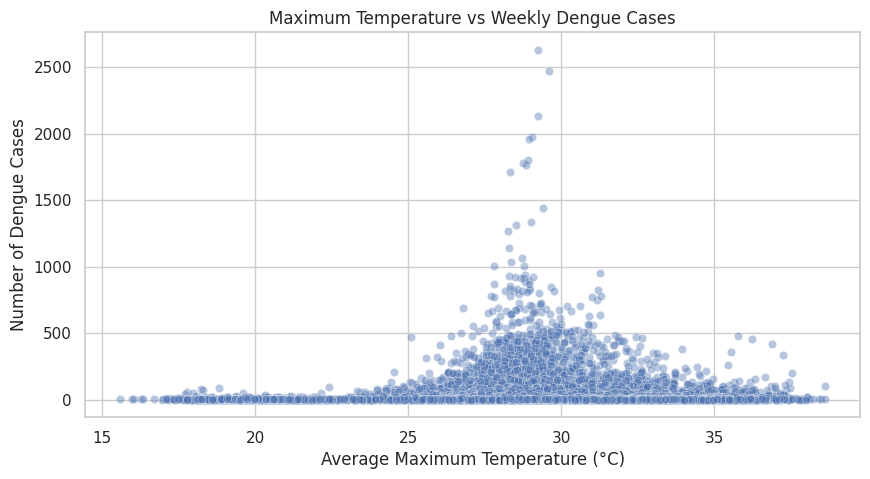

In [ ]:
# Relationship between maximum temperature and dengue cases
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x="Avg Max Temp (°C)",
    y="Number_of_Cases",
    alpha=0.4
)

plt.title("Maximum Temperature vs Weekly Dengue Cases")
plt.xlabel("Average Maximum Temperature (°C)")
plt.ylabel("Number of Dengue Cases")
plt.show()

**Maximum Temperature Analysis:** The scatter plot shows that most observations are concentrated between 25°C and 32°C. Higher dengue case counts are mainly observed around 28°C–30°C. However, the relationship does not follow a clear linear pattern, as considerable variation exists across temperature values. This suggests that maximum temperature alone may not sufficiently explain variations in dengue cases.

7.5.3 Minimum Temperature vs Dengue Cases

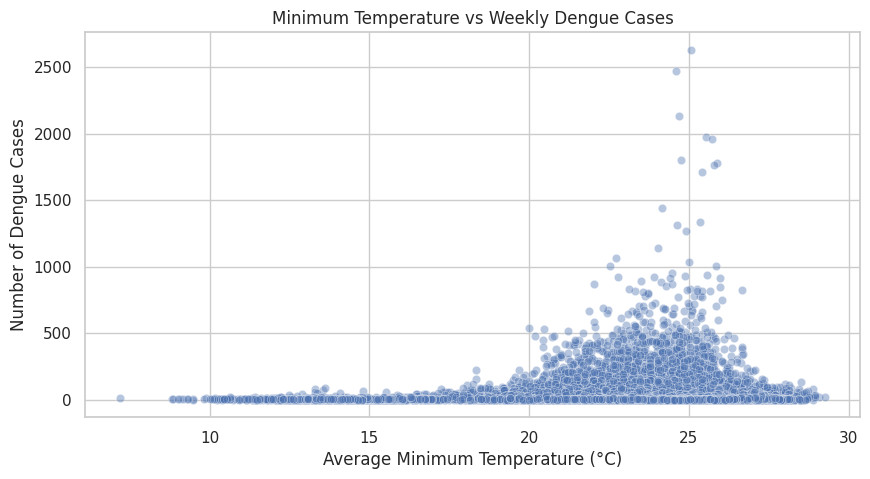

In [ ]:
# Relationship between minimum temperature and dengue cases
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x="Avg Min Temp (°C)",
    y="Number_of_Cases",
    alpha=0.4
)

plt.title("Minimum Temperature vs Weekly Dengue Cases")
plt.xlabel("Average Minimum Temperature (°C)")
plt.ylabel("Number of Dengue Cases")
plt.show()

**Maximum Temperature Analysis:** The scatter plot shows that most observations are concentrated between 20°C and 28°C. Higher dengue case counts are mainly observed between approximately 22°C and 26°C, with extreme outbreak values occurring around 24.5°C–25.5°C. However, dengue cases generally appear lower at minimum temperatures above approximately 27°C. The relationship does not follow a clear linear pattern and appears to exhibit a non-linear, approximately hump-shaped pattern. Considerable variation in dengue cases is also observed across similar temperature values, suggesting that minimum temperature alone may not sufficiently explain variations in dengue cases.

7.5.4 Wind Speed vs Dengue Cases

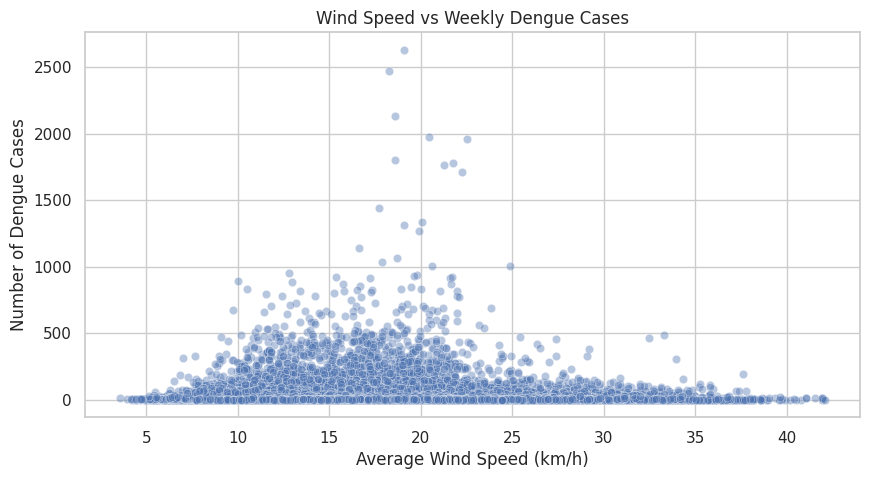

In [ ]:
# Relationship between wind speed and dengue cases
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x="Avg Wind Speed (km/h)",
    y="Number_of_Cases",
    alpha=0.4
)

plt.title("Wind Speed vs Weekly Dengue Cases")
plt.xlabel("Average Wind Speed (km/h)")
plt.ylabel("Number of Dengue Cases")
plt.show()

**Wind Speed Analysis:** The scatter plot shows that most observations are concentrated between approximately 10 km/h and 25 km/h. Higher dengue case counts are mainly observed between approximately 12 km/h and 22 km/h, with extreme outbreak values occurring around 17 km/h to 22 km/h. However, dengue cases generally appear lower at wind speeds above approximately 25 km/h. The relationship does not follow a clear linear pattern, as considerable variation exists across wind speed values. This suggests that average wind speed alone may not sufficiently explain variations in dengue cases.


7.5.5 Maximum Wind Gusts vs Dengue Cases

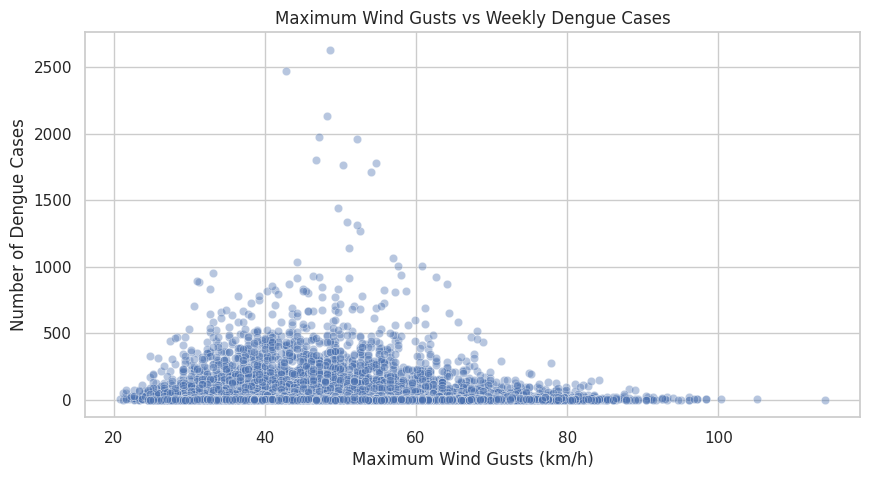

In [ ]:
# Relationship between maximum wind gusts and dengue cases
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x="Max Wind Gusts (km/h)",
    y="Number_of_Cases",
    alpha=0.4
)

plt.title("Maximum Wind Gusts vs Weekly Dengue Cases")
plt.xlabel("Maximum Wind Gusts (km/h)")
plt.ylabel("Number of Dengue Cases")
plt.show()

**Maximum Wind Gusts Analysis:** The scatter plot shows that most observations are concentrated between approximately 25 km/h and 60 km/h. Higher dengue case counts are mainly observed between approximately 35 km/h and 60 km/h, with extreme outbreak values occurring around 45 km/h to 55 km/h. However, dengue cases generally appear lower at maximum wind gust speeds above approximately 70 km/h. The relationship does not follow a clear linear pattern, as considerable variation exists across wind gust values. This suggests that maximum wind gusts alone may not sufficiently explain variations in dengue cases.

7.5.6 Daylight Duration vs Dengue Cases

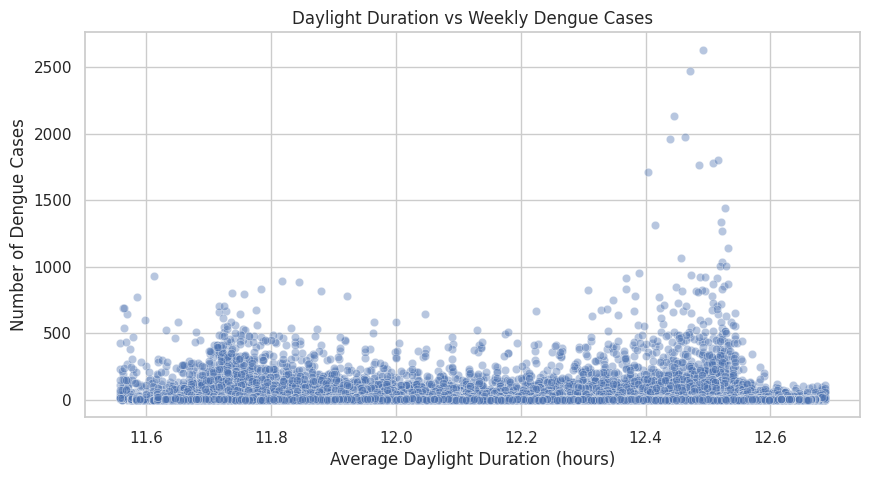

In [ ]:
# Relationship between daylight duration and dengue cases
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x="Avg Daylight Duration (hours)",
    y="Number_of_Cases",
    alpha=0.4
)

plt.title("Daylight Duration vs Weekly Dengue Cases")
plt.xlabel("Average Daylight Duration (hours)")
plt.ylabel("Number of Dengue Cases")
plt.show()

**Daylight Duration Analysis:** The scatter plot shows that most observations are concentrated between approximately 11.7 and 12.6 hours of daylight duration. Higher dengue case counts are mainly observed around 12.4 to 12.55 hours, with several extreme outbreak values occurring within this range. However, considerable variation in dengue cases exists across daylight duration values, and higher case counts are also observed at shorter daylight durations. The relationship does not follow a clear linear pattern, suggesting that daylight duration alone may not sufficiently explain variations in dengue cases.

### 7.6 Correlation Analysis

This section examines the correlations between dengue cases and weather-related features using a correlation matrix. A heatmap is used to visualize the strength and direction of relationships between numerical variables.

In [ ]:
# Select numerical features for correlation analysis
correlation_features = [
    "Number_of_Cases",
    "Avg Max Temp (°C)",
    "Avg Min Temp (°C)",
    "Avg Apparent Max Temp (°C)",
    "Avg Apparent Min Temp (°C)",
    "Total Precipitation (mm)",
    "Avg Wind Speed (km/h)",
    "Max Wind Gusts (km/h)",
    "Avg Daylight Duration (hours)"
]

# Calculate correlation matrix
correlation_matrix = df[correlation_features].corr()

# Display correlation matrix
display(correlation_matrix)

,Number_of_Cases,Avg Max Temp (°C),Avg Min Temp (°C),Avg Apparent Max Temp (°C),Avg Apparent Min Temp (°C),Total Precipitation (mm),Avg Wind Speed (km/h),Max Wind Gusts (km/h),Avg Daylight Duration (hours)
Number_of_Cases,1.000000,-0.034000,0.026170,0.008517,0.058440,0.085365,-0.012950,-0.007687,0.005618
Avg Max Temp (°C),-0.034000,1.000000,0.727333,0.921073,0.722583,-0.369072,0.223714,0.023632,0.349144
Avg Min Temp (°C),0.026170,0.727333,1.000000,0.716582,0.955221,-0.136555,0.531923,0.166025,0.351618
Avg Apparent Max Temp (°C),0.008517,0.921073,0.716582,1.000000,0.802592,-0.208669,-0.018156,-0.215192,0.286453
Avg Apparent Min Temp (°C),0.058440,0.722583,0.955221,0.802592,1.000000,-0.049147,0.297239,-0.020128,0.286781
Total Precipitation (mm),0.085365,-0.369072,-0.136555,-0.208669,-0.049147,1.000000,-0.229031,-0.088415,-0.177049
Avg Wind Speed (km/h),-0.012950,0.223714,0.531923,-0.018156,0.297239,-0.229031,1.000000,0.724715,0.375741
Max Wind Gusts (km/h),-0.007687,0.023632,0.166025,-0.215192,-0.020128,-0.088415,0.724715,1.000000,0.415905
Avg Daylight Duration (hours),0.005618,0.349144,0.351618,0.286453,0.286781,-0.177049,0.375741,0.415905,1.000000


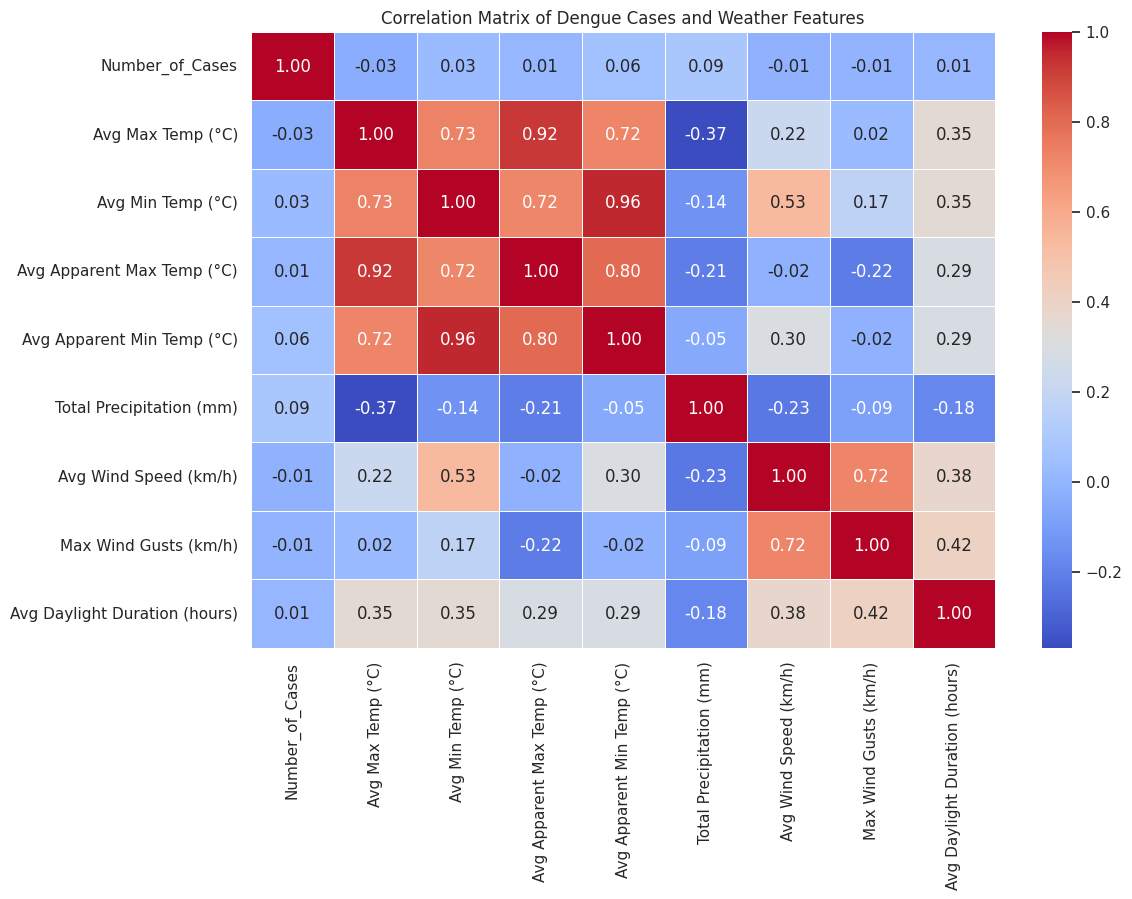

In [ ]:
# Plot correlation heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Dengue Cases and Weather Features")
plt.show()

**Correlation Analysis:** The correlations between weekly dengue cases and each same-week weather variable are very close to zero. The strongest is total precipitation (r = 0.09), followed by average apparent minimum temperature (r = 0.06) and average minimum temperature (r = 0.03); maximum temperature (r = −0.03), wind speed (r = −0.01), wind gusts (r = −0.01) and daylight duration (r = 0.01) show practically no linear association. Several weather variables are strongly inter-correlated: maximum and apparent maximum temperature (r = 0.92), minimum and apparent minimum temperature (r = 0.96), and wind speed and wind gusts (r = 0.72). The apparent temperature variables are therefore almost redundant.

These near-zero correlations do not prove that weather has no effect. Pearson correlation captures only same-week linear association, whereas dengue transmission responds to weather with a delay, the scatter plots suggest non-linear patterns, and pooling 25 districts with very different case levels can weaken apparent relationships. The heatmap shows association, not causation. Lagged weather effects are therefore examined in Section 7.7.

### 7.7 Lagged Weather Analysis

Same-week weather variables show almost no correlation with dengue cases. However, dengue transmission depends on the mosquito life cycle and the incubation period, so weather may influence case counts only after several weeks. This section examines the correlation between current dengue cases and weather values from previous weeks, calculated within each district to avoid mixing differences between districts.

Lag-1 autocorrelation of cases (mean across districts): 0.85


,Rainfall,Max Temp
Lag (weeks),,
0,0.012,-0.030
1,0.034,-0.041
2,0.057,-0.049
3,0.077,-0.056
4,0.094,-0.058
5,0.130,-0.065
6,0.154,-0.060
7,0.172,-0.050
8,0.184,-0.033


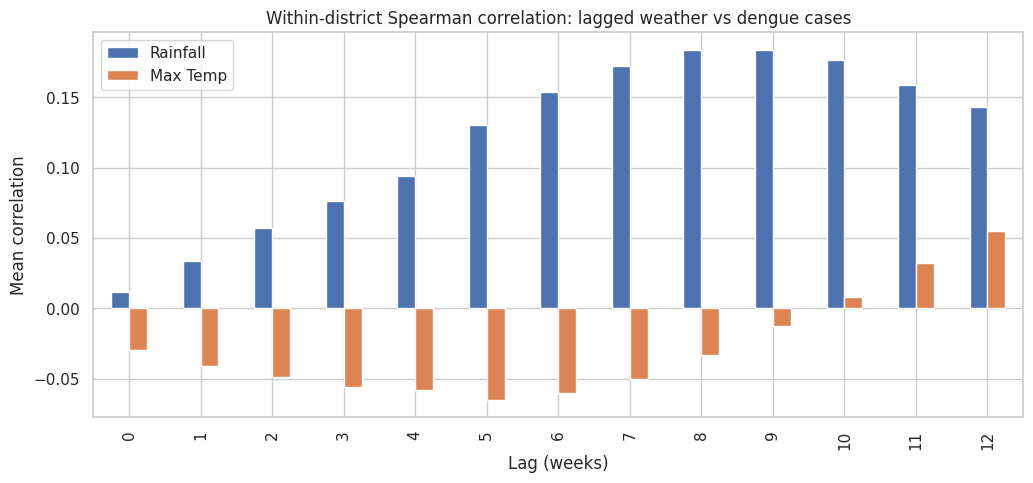

In [ ]:
RAIN = "Total Precipitation (mm)"
TEMP = "Avg Max Temp (°C)"

# Sort so that shifting works in time order within each district
df = df.sort_values(["District", "Week_Start_Date"]).reset_index(drop=True)

# 1. Autocorrelation of cases (previous week vs current week), within districts
autocorr_lag1 = df.groupby("District")["Number_of_Cases"].apply(lambda s: s.autocorr(1))
print("Lag-1 autocorrelation of cases (mean across districts):", round(autocorr_lag1.mean(), 3))

# 2. Weather lag correlations (Spearman), calculated inside each district then averaged
rows = []
for lag in range(0, 13):
    rain_corr = df.groupby("District").apply(
        lambda d: d["Number_of_Cases"].corr(d[RAIN].shift(lag), method="spearman")).mean()
    temp_corr = df.groupby("District").apply(
        lambda d: d["Number_of_Cases"].corr(d[TEMP].shift(lag), method="spearman")).mean()
    rows.append((lag, rain_corr, temp_corr))

lag_corr = pd.DataFrame(rows, columns=["Lag (weeks)", "Rainfall", "Max Temp"]).set_index("Lag (weeks)")
display(lag_corr.round(3))

lag_corr.plot(kind="bar", figsize=(12, 5),
              title="Within-district Spearman correlation: lagged weather vs dengue cases")
plt.xlabel("Lag (weeks)"); plt.ylabel("Mean correlation"); plt.show()

**Lagged Weather Analysis:** Rainfall shows almost no association with dengue cases in the same week (ρ = 0.012), but the association strengthens with the lag and peaks at 8–9 weeks (ρ = 0.184) before declining. Maximum temperature shows only weak associations (between −0.065 and +0.055) whose sign changes with the lag. The lag-1 autocorrelation of weekly cases within districts is 0.85, indicating that dengue cases persist strongly from one week to the next.

These results are associations, not proof of causation. A peak at 8–9 weeks is longer than the mosquito life cycle alone would suggest, and part of it may reflect shared seasonality (e.g. monsoon periods) and the gradual accumulation of breeding sites.

**Implications for feature engineering:** lagged case counts, rainfall lags of up to 10 weeks and rolling rainfall sums are included as features, together with a small number of temperature lags.

## 8. Feature Engineering

This section converts the weekly records into a supervised learning dataset.   A single weekly record only describes one week, but forecasting next week's cases requires information about the recent past. Therefore, values from previous weeks are added to each record as new columns. A **lag** of *k* weeks means the value observed *k* weeks before the current week; for example, `cases_lag1` is the previous week's number of cases and `rain_lag8` is the rainfall eight weeks earlier.All features are calculated using only information available up to the current week:

The choice of features is based on the findings of the exploratory analysis, in particular the lagged weather analysis in Section 7.7.

- **Lagged dengue cases** (1, 2, 4, 8 and 12 weeks) and a 4-week rolling mean of previous cases, because dengue cases show strong persistence (lag-1 autocorrelation of 0.85).
- **Lagged rainfall** (2, 4, 6, 8 and 10 weeks) and **rolling rainfall totals** (4, 8 and 12 weeks), because the lagged analysis showed that rainfall is associated with later dengue cases, peaking at 8–9 weeks.
- **Lagged maximum temperature** (4 and 8 weeks), included because temperature shows only weak associations.
- **Seasonal features:** cyclical encoding of the week number.
- **District identifier:** a numeric code for each district.

All lag and rolling features are calculated separately within each district, and rolling features exclude the current week, so no future information is used.

In [ ]:

RAIN = "Total Precipitation (mm)"
TEMP = "Avg Max Temp (°C)"

# Make sure data is in time order within each district
df = df.sort_values(
    ["District", "Week_Start_Date"]
).reset_index(drop=True)

# Work on a copy
fe = df.copy()
g = fe.groupby("District")

# 1. Lagged dengue cases
for lag in [1, 2, 4, 8, 12]:
    fe[f"cases_lag{lag}"] = g["Number_of_Cases"].shift(lag)

# 2. Rolling mean of previous 4 weeks
fe["cases_roll4_mean"] = g["Number_of_Cases"].transform(
    lambda s: s.shift(1).rolling(4).mean()
)

# 3. Lagged rainfall
for lag in [2, 4, 6, 8, 10]:
    fe[f"rain_lag{lag}"] = g[RAIN].shift(lag)

# 4. Rolling rainfall totals
for window in [4, 8, 12]:
    fe[f"rain_sum{window}"] = g[RAIN].transform(
        lambda s: s.shift(1).rolling(window).sum()
    )

# 5. Lagged maximum temperature
for lag in [4, 8]:
    fe[f"maxtemp_lag{lag}"] = g[TEMP].shift(lag)

# 6. Next-week target
fe["target_next_week_cases"] = (
    g["Number_of_Cases"].shift(-1)
)

# 7. Seasonal features
fe["Week_sin"] = np.sin(2 * np.pi * fe["Week"] / 52)
fe["Week_cos"] = np.cos(2 * np.pi * fe["Week"] / 52)

# 8. District encoding
fe["District_code"] = fe["District"].astype("category").cat.codes

# Required columns for model preparation
required_columns = [
    "cases_lag1", "cases_lag2", "cases_lag4",
    "cases_lag8", "cases_lag12", "cases_roll4_mean",
    "rain_lag2", "rain_lag4", "rain_lag6",
    "rain_lag8", "rain_lag10",
    "rain_sum4", "rain_sum8", "rain_sum12",
    "maxtemp_lag4", "maxtemp_lag8",
    "Week_sin", "Week_cos", "District_code",
    "target_next_week_cases"
]

# Remove rows with missing required features or target
rows_before = len(fe)

fe = fe.dropna(subset=required_columns).reset_index(drop=True)

# Display dataset information
print("Rows before:", rows_before)
print("Rows after:", len(fe))
print("Dataset shape:", fe.shape)
print("Weeks per district:", fe.groupby("District").size().unique())

print(
    "Date range:",
    fe["Week_Start_Date"].min().date(),
    "to",
    fe["Week_Start_Date"].max().date()
)

display(fe.head())


Rows before: 22900
Rows after: 22575
Dataset shape: (22575, 36)
Weeks per district: [903]
Date range: 2007-03-26 to 2024-07-08


,District,Number_of_Cases,Week_Start_Date,Month,Year,Week,Week_End_Date,Avg Max Temp (°C),Avg Min Temp (°C),Avg Apparent Max Temp (°C),Avg Apparent Min Temp (°C),Total Precipitation (mm),Avg Wind Speed (km/h),Max Wind Gusts (km/h),Weather Code,Avg Daylight Duration (hours),cases_lag1,cases_lag2,cases_lag4,cases_lag8,cases_lag12,cases_roll4_mean,rain_lag2,rain_lag4,rain_lag6,rain_lag8,rain_lag10,rain_sum4,rain_sum8,rain_sum12,maxtemp_lag4,maxtemp_lag8,target_next_week_cases,Week_sin,Week_cos,District_code
0,Ampara,0,2007-03-26,3,2007,13,2007-04-02,31.0750,22.6500,36.7250,26.750,2.2,13.2250,33.5,1,12.170833,0.0,0.0,1.0,0.0,0.0,0.25,16.2,3.9,5.3,8.2,3.1,25.6,57.8,208.6,29.2875,27.3625,0.0,1.000000,-1.608123e-16,0
1,Ampara,0,2007-04-02,4,2007,14,2007-04-09,29.5750,24.4250,35.1000,29.475,89.7,12.5375,36.0,63,12.216667,0.0,0.0,0.0,0.0,0.0,0.00,0.0,5.5,8.4,10.3,53.6,23.9,51.8,202.8,29.1500,27.8625,0.0,0.992709,-1.205367e-01,0
2,Ampara,0,2007-04-09,4,2007,15,2007-04-16,28.1875,23.9500,33.5875,28.500,104.0,11.9500,35.6,61,12.262500,0.0,0.0,0.0,0.0,0.0,0.00,2.2,16.2,3.9,5.3,8.2,108.1,131.2,206.4,29.3250,29.0000,0.0,0.970942,-2.393157e-01,0
3,Ampara,0,2007-04-16,4,2007,16,2007-04-23,30.5750,24.8125,37.4750,29.925,16.9,9.7000,31.3,53,12.306250,0.0,0.0,0.0,0.0,0.0,0.00,89.7,0.0,5.5,8.4,10.3,195.9,229.9,307.3,30.8125,27.9375,0.0,0.935016,-3.546049e-01,0
4,Ampara,0,2007-04-23,4,2007,17,2007-04-30,31.1500,24.7625,38.6250,30.050,25.3,10.2250,29.2,53,12.350000,0.0,0.0,0.0,1.0,0.0,0.00,104.0,2.2,16.2,3.9,5.3,212.8,238.4,270.6,31.0750,29.2875,0.0,0.885456,-4.647232e-01,0


## 9. Chronological Train / Validation / Test Split

Because the data form a time series, the dataset is split chronologically rather than randomly, so that models are always trained on the past and evaluated on later periods they have never seen. This avoids leakage of future information.

- **Training set:** 2007-03-26 to 2020-12-28
- **Validation set:** 2021-01-04 to 2022-12-26 (used only for hyperparameter tuning and model selection)
- **Test set:** 2023-01-02 to 2024-07-08 (used only for the final comparison)
- **Stacking and hybrid models.** The meta-learner of the stacking ensemble is trained on out-of-fold predictions generated inside the training period using chronological cross-validation, and the residual-correction component of the hybrid ARIMA + Random Forest model is also trained only on the training period. The validation set is therefore not used to fit these components, and the test set is used only once for the final comparison.

**Dates and assumptions.** The date ranges above refer to the dates of the feature rows; each target is the number of cases in the following week, i.e. seven days later. For example, the target of the last training row (week of 2020-12-28) is the case count of the first validation week. It is also assumed that the current week's case count is already available when the next week is predicted; in practice, reporting delays could reduce the usable lead time.

**Feature selection:** The current week's cases, lagged cases, the rolling case mean, current and lagged weather features, seasonal features and the district code are used. Apparent temperatures (r = 0.92 and 0.96 with the actual temperatures), maximum wind gusts (r = 0.72 with wind speed) and daylight duration (almost entirely seasonal) are excluded as redundant. The year is excluded so that models cannot rely on a time trend that does not extend into unseen periods.

In [ ]:
# Sort by date so that the split is strictly chronological
fe = fe.sort_values(["Week_Start_Date", "District"]).reset_index(drop=True)

# Feature list (original column names kept)
feature_cols = [
    # Dengue case history (current week is known when predicting next week)
    "Number_of_Cases", "cases_lag1", "cases_lag2", "cases_lag4",
    "cases_lag8", "cases_lag12", "cases_roll4_mean",
    # Current weather
    "Total Precipitation (mm)", "Avg Max Temp (°C)", "Avg Min Temp (°C)", "Avg Wind Speed (km/h)",
    # Lagged and rolling weather
    "rain_lag2", "rain_lag4", "rain_lag6", "rain_lag8", "rain_lag10",
    "rain_sum4", "rain_sum8", "rain_sum12",
    "maxtemp_lag4", "maxtemp_lag8",
    # Seasonal and district
    "Week_sin", "Week_cos", "District_code",
]
target_col = "target_next_week_cases"

# Chronological split
train_df = fe[fe["Week_Start_Date"] < "2021-01-01"]
val_df   = fe[(fe["Week_Start_Date"] >= "2021-01-01") & (fe["Week_Start_Date"] < "2023-01-01")]
test_df  = fe[fe["Week_Start_Date"] >= "2023-01-01"]

X_train, y_train = train_df[feature_cols], train_df[target_col]
X_val,   y_val   = val_df[feature_cols],   val_df[target_col]
X_test,  y_test  = test_df[feature_cols],  test_df[target_col]

print("Number of features:", len(feature_cols))
for name, d in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    print(f"{name:11s} rows: {len(d):6d} | {d['Week_Start_Date'].min().date()} to {d['Week_Start_Date'].max().date()} "
          f"| weeks: {d['Week_Start_Date'].nunique()} | mean next-week cases: {d[target_col].mean():.1f}")

Number of features: 24
Train       rows:  17975 | 2007-03-26 to 2020-12-28 | weeks: 719 | mean next-week cases: 32.1
Validation  rows:   2600 | 2021-01-04 to 2022-12-26 | weeks: 104 | mean next-week cases: 38.0
Test        rows:   2000 | 2023-01-02 to 2024-07-08 | weeks: 80 | mean next-week cases: 59.4


## 10. Baseline Models

Baseline models provide simple benchmarks against which the more complex models are judged. Two baselines are used: a Naive Forecast and a Linear Regression.

### 10.1 Naive Forecast

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Table to store the results of ALL models (we will keep adding to it)
results = []

def evaluate_model(model_name, dataset_name, y_true, y_pred):
    """Calculate MAE, RMSE and R2 and store them in the results list."""
    results.append({
        "Model": model_name,
        "Dataset": dataset_name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    })

# Naive forecast: next week's cases = current week's cases
naive_val_pred  = val_df["Number_of_Cases"]
naive_test_pred = test_df["Number_of_Cases"]

evaluate_model("Naive", "Validation", y_val,  naive_val_pred)
evaluate_model("Naive", "Test",       y_test, naive_test_pred)

results_df = pd.DataFrame(results)
display(results_df.round(3))

,Model,Dataset,MAE,RMSE,R2
0,Naive,Validation,10.787,27.025,0.88
1,Naive,Test,13.571,27.419,0.92


### 10.2 Linear Regression

Linear Regression is used as a linear benchmark. It learns a weight (coefficient) for each input feature and predicts next week's cases as a weighted sum of these features, so it captures only linear relationships.

Linear Regression treats numeric inputs as quantities, so the numeric `District_code` is not suitable for this model: it would imply that district 10 is "twice" district 5. Instead, the district is converted into binary (one-hot) indicator columns. Because dengue counts cannot be negative, negative predictions are replaced by zero. The model is fitted on the training set only, and evaluated on the validation and test sets.

In [ ]:
from sklearn.linear_model import LinearRegression

# Features for Linear Regression: remove the numeric district code
lin_features = [c for c in feature_cols if c != "District_code"]

def make_linear_matrix(d):
    """Numeric features + one-hot district columns"""
    districts = pd.get_dummies(d["District"], prefix="District", drop_first=True).astype(float)
    return pd.concat([d[lin_features], districts], axis=1)

X_train_lin = make_linear_matrix(train_df)
X_val_lin   = make_linear_matrix(val_df).reindex(columns=X_train_lin.columns, fill_value=0)
X_test_lin  = make_linear_matrix(test_df).reindex(columns=X_train_lin.columns, fill_value=0)
print("Linear Regression input shapes:", X_train_lin.shape, X_val_lin.shape, X_test_lin.shape)

# Train on the training set only
lin_model = LinearRegression()
lin_model.fit(X_train_lin, y_train)

# Predict (cases cannot be negative, so clip at 0)
lin_val_raw  = lin_model.predict(X_val_lin)
lin_test_raw = lin_model.predict(X_test_lin)
print("Share of negative predictions - validation: {:.1%}, test: {:.1%}".format(
    (lin_val_raw < 0).mean(), (lin_test_raw < 0).mean()))

lin_val_pred  = np.clip(lin_val_raw, 0, None)
lin_test_pred = np.clip(lin_test_raw, 0, None)

evaluate_model("Linear Regression", "Validation", y_val,  lin_val_pred)
evaluate_model("Linear Regression", "Test",       y_test, lin_test_pred)

results_df = pd.DataFrame(results)
display(results_df.round(3))

Linear Regression input shapes: (17975, 47) (2600, 47) (2000, 47)
Share of negative predictions - validation: 6.5%, test: 2.5%


,Model,Dataset,MAE,RMSE,R2
0,Naive,Validation,10.787,27.025,0.880
1,Naive,Test,13.571,27.419,0.920
2,Linear Regression,Validation,11.101,26.543,0.884
3,Linear Regression,Test,13.200,25.870,0.929


### 10.3 Baseline Performance Comparison

This section compares the two baseline models. Their MAE and RMSE form the benchmark that the ensemble and hybrid models must improve on.


MAE


Dataset,Validation,Test
Model,,
Linear Regression,11.101,13.200
Naive,10.787,13.571



RMSE


Dataset,Validation,Test
Model,,
Linear Regression,26.543,25.870
Naive,27.025,27.419



R2


Dataset,Validation,Test
Model,,
Linear Regression,0.884,0.929
Naive,0.880,0.920



Linear Regression vs Naive:


,MAE change vs Naive (%),RMSE change vs Naive (%)
Dataset,,
Validation,2.9,-1.8
Test,-2.7,-5.6


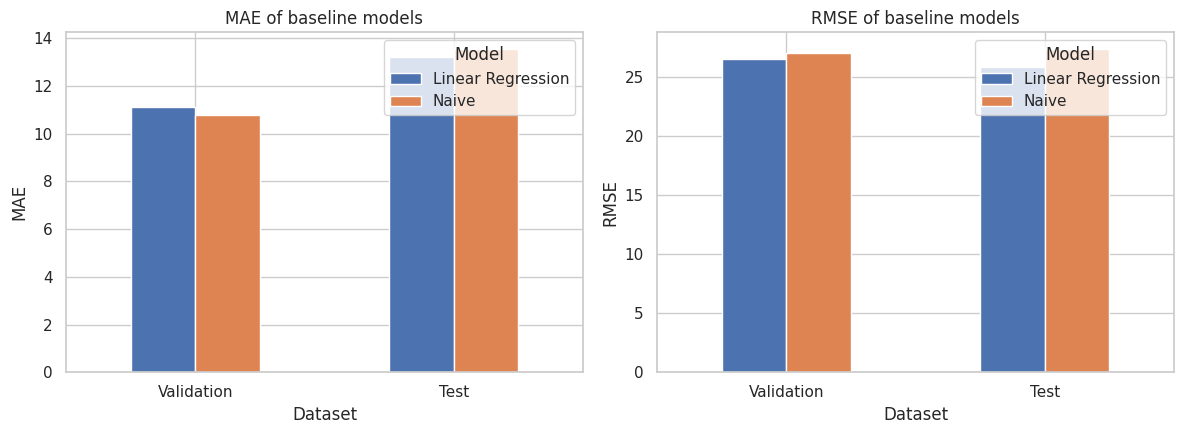

In [ ]:
baseline_df = pd.DataFrame(results)

# Tables per metric
for metric in ["MAE", "RMSE", "R2"]:
    print(f"\n{metric}")
    display(baseline_df.pivot(index="Model", columns="Dataset", values=metric)[["Validation", "Test"]].round(3))

# Percentage change of Linear Regression relative to Naive (negative = better for MAE/RMSE)
naive = baseline_df[baseline_df["Model"] == "Naive"].set_index("Dataset")
lin   = baseline_df[baseline_df["Model"] == "Linear Regression"].set_index("Dataset")
change = ((lin[["MAE", "RMSE"]] - naive[["MAE", "RMSE"]]) / naive[["MAE", "RMSE"]] * 100).round(1)
change.columns = ["MAE change vs Naive (%)", "RMSE change vs Naive (%)"]
print("\nLinear Regression vs Naive:")
display(change)

# Bar charts
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for a, metric in zip(ax, ["MAE", "RMSE"]):
    baseline_df.pivot(index="Dataset", columns="Model", values=metric).loc[["Validation", "Test"]].plot.bar(ax=a, rot=0)
    a.set_title(f"{metric} of baseline models"); a.set_ylabel(metric)
plt.tight_layout(); plt.show()

**Baseline Comparison:** The two baseline models perform very similarly.

## 11. Random Forest (Bagging)

Random Forest is a bagging ensemble.

### 11.1 Random Forest with initial settings

An initial Random Forest is trained on the training set and evaluated on the validation set only. The test set is not used until the hyperparameters have been selected. The training-set errors are also reported to check for overfitting.

In [ ]:
from sklearn.ensemble import RandomForestRegressor
import time

# Initial Random Forest (settings chosen as reasonable defaults, tuned later)
rf_initial = RandomForestRegressor(
    n_estimators=300,        # number of trees
    min_samples_leaf=3,      # each leaf must contain at least 3 samples
    max_features=0.5,        # each split considers 50% of the features
    random_state=42,
    n_jobs=-1
)

start = time.time()
rf_initial.fit(X_train, y_train)
print(f"Training time: {time.time() - start:.1f} seconds")

# Evaluate on training and validation sets
rf_train_pred = rf_initial.predict(X_train)
rf_val_pred   = rf_initial.predict(X_val)

print("\nTraining set:   MAE={:.3f}  RMSE={:.3f}  R2={:.3f}".format(
    mean_absolute_error(y_train, rf_train_pred),
    np.sqrt(mean_squared_error(y_train, rf_train_pred)),
    r2_score(y_train, rf_train_pred)))
print("Validation set: MAE={:.3f}  RMSE={:.3f}  R2={:.3f}".format(
    mean_absolute_error(y_val, rf_val_pred),
    np.sqrt(mean_squared_error(y_val, rf_val_pred)),
    r2_score(y_val, rf_val_pred)))

# Store the validation result for the final comparison table
evaluate_model("Random Forest (initial)", "Validation", y_val, rf_val_pred)
display(pd.DataFrame(results).query("Dataset == 'Validation'").round(3))

Training time: 97.1 seconds

Training set:   MAE=4.947  RMSE=14.922  R2=0.971
Validation set: MAE=10.633  RMSE=26.031  R2=0.889


,Model,Dataset,MAE,RMSE,R2
0,Naive,Validation,10.787,27.025,0.880
2,Linear Regression,Validation,11.101,26.543,0.884
4,Random Forest (initial),Validation,10.633,26.031,0.889


**Initial Random Forest Results:** On the validation set the initial Random Forest achieves an MAE of 10.63, an RMSE of 26.03 and an R² of 0.889. This is slightly better than the Naive Forecast (MAE 10.79, RMSE 27.03; 1.4% and 3.7% lower) and Linear Regression (MAE 11.10, RMSE 26.54; 4.2% and 1.9% lower), but the improvement is small, which again reflects the strong persistence of dengue cases. The training errors (MAE 4.95, RMSE 14.92, R² 0.971) are much lower than the validation errors; since a Random Forest is evaluated on data it has already seen when predicting the training set, part of this gap is expected, but it also suggests that the model may benefit from stronger regularisation, which is examined through hyperparameter tuning.

### 11.2 Random Forest Hyperparameter Tuning

The initial Random Forest showed a small improvement over both baseline models on the validation set. However, the difference between training and validation performance suggests possible overfitting. Therefore, selected hyperparameters are tuned to improve generalisation.



In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import time

# Hyperparameter combinations
rf_configs = [
    {"n_estimators": 200, "max_depth": 10,   "min_samples_leaf": 5,  "max_features": 0.5},
    {"n_estimators": 300, "max_depth": 15,   "min_samples_leaf": 5,  "max_features": 0.5},
    {"n_estimators": 300, "max_depth": 20,   "min_samples_leaf": 3,  "max_features": 0.5},
    {"n_estimators": 300, "max_depth": None, "min_samples_leaf": 5,  "max_features": 0.5},
    {"n_estimators": 400, "max_depth": 15,   "min_samples_leaf": 3,  "max_features": 0.7},
    # added: stronger regularisation (larger leaves)
    {"n_estimators": 300, "max_depth": None, "min_samples_leaf": 10, "max_features": 0.5},
    {"n_estimators": 300, "max_depth": None, "min_samples_leaf": 30, "max_features": 0.5},
]

rf_tuning_results = []

for i, params in enumerate(rf_configs, start=1):
    model = RandomForestRegressor(**params, random_state=42, n_jobs=-1)

    start = time.time()
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    rf_tuning_results.append({
        "Configuration": i,
        "Parameters": str(params),
        "Train_MAE": mean_absolute_error(y_train, train_pred),
        "Val_MAE": mean_absolute_error(y_val, val_pred),
        "Val_RMSE": np.sqrt(mean_squared_error(y_val, val_pred)),
        "Val_R2": r2_score(y_val, val_pred),
        "Time_sec": round(time.time() - start, 1)
    })
    print(f"Configuration {i} done ({rf_tuning_results[-1]['Time_sec']} s)")

rf_tuning_df = pd.DataFrame(rf_tuning_results)

display(
    rf_tuning_df.drop(columns=["Parameters"])
    .sort_values("Val_MAE")
    .round(3)
)

print("\nFull configuration details:")
display(rf_tuning_df[["Configuration", "Parameters"]])

# Select the configuration with the lowest validation MAE
best_idx = int(rf_tuning_df.sort_values("Val_MAE").iloc[0]["Configuration"])
best_rf_params = rf_configs[best_idx - 1]
print("\nBest configuration (lowest validation MAE): Configuration", best_idx)
print(best_rf_params)

Configuration 1 done (22.4 s)
Configuration 2 done (58.0 s)
Configuration 3 done (60.5 s)
Configuration 4 done (57.6 s)
Configuration 5 done (85.4 s)
Configuration 6 done (44.3 s)
Configuration 7 done (34.0 s)


,Configuration,Train_MAE,Val_MAE,Val_RMSE,Val_R2,Time_sec
4,5,5.660,10.573,25.618,0.892,85.4
1,2,6.592,10.596,25.968,0.889,58.0
0,1,7.906,10.597,26.084,0.888,22.4
3,4,6.179,10.605,25.927,0.889,57.6
2,3,5.056,10.713,26.123,0.888,60.5
5,6,7.792,10.713,26.563,0.884,44.3
6,7,9.673,10.957,27.867,0.872,34.0



Full configuration details:


,Configuration,Parameters
0,1,"{'n_estimators': 200, 'max_depth': 10, 'min_sa..."
1,2,"{'n_estimators': 300, 'max_depth': 15, 'min_sa..."
2,3,"{'n_estimators': 300, 'max_depth': 20, 'min_sa..."
3,4,"{'n_estimators': 300, 'max_depth': None, 'min_..."
4,5,"{'n_estimators': 400, 'max_depth': 15, 'min_sa..."
5,6,"{'n_estimators': 300, 'max_depth': None, 'min_..."
6,7,"{'n_estimators': 300, 'max_depth': None, 'min_..."



Best configuration (lowest validation MAE): Configuration 5
{'n_estimators': 400, 'max_depth': 15, 'min_samples_leaf': 3, 'max_features': 0.7}


### 11.3 Final Random Forest Evaluation

The best hyperparameter configuration was selected based on validation performance. The final Random Forest model is trained using the training set with the selected parameters and evaluated on the validation and test sets.

The test set is used at this stage for the final performance assessment. Feature importance is also examined to identify the variables that contribute most to the model's predictions.

Final RF training time: 82.7 seconds

Training Set:
MAE  : 5.660
RMSE : 15.094
R2   : 0.971

Validation Set:
MAE  : 10.573
RMSE : 25.618
R2   : 0.892

Test Set:
MAE  : 13.821
RMSE : 28.191
R2   : 0.915

Top 15 Important Features (impurity-based):


,Feature,Importance
0,Number_of_Cases,0.6254
1,cases_lag1,0.2133
6,cases_roll4_mean,0.0431
2,cases_lag2,0.0392
3,cases_lag4,0.0105
17,rain_sum8,0.0088
22,Week_cos,0.0071
20,maxtemp_lag8,0.0058
12,rain_lag4,0.0048
15,rain_lag10,0.0047


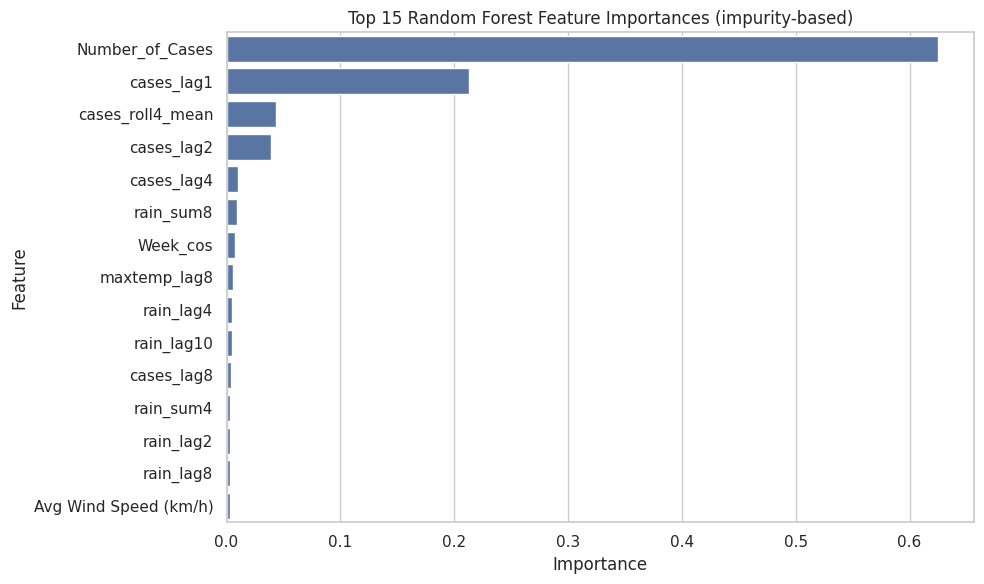

In [ ]:
# Final Random Forest using the best configuration
rf_best = RandomForestRegressor(
    n_estimators=400,
    max_depth=15,
    min_samples_leaf=3,
    max_features=0.7,
    random_state=42,
    n_jobs=-1
)

start = time.time()
rf_best.fit(X_train, y_train)
print(f"Final RF training time: {time.time() - start:.1f} seconds")

# Predictions
rf_best_train_pred = rf_best.predict(X_train)
rf_best_val_pred = rf_best.predict(X_val)
rf_best_test_pred = rf_best.predict(X_test)

# Evaluate all three datasets
for name, actual, predicted in [
    ("Training", y_train, rf_best_train_pred),
    ("Validation", y_val, rf_best_val_pred),
    ("Test", y_test, rf_best_test_pred)
]:
    print(f"\n{name} Set:")
    print(f"MAE  : {mean_absolute_error(actual, predicted):.3f}")
    print(f"RMSE : {np.sqrt(mean_squared_error(actual, predicted)):.3f}")
    print(f"R2   : {r2_score(actual, predicted):.3f}")

# Store final validation and test results
evaluate_model("Random Forest (Tuned)", "Validation", y_val, rf_best_val_pred)
evaluate_model("Random Forest (Tuned)", "Test", y_test, rf_best_test_pred)

# Impurity-based feature importance
rf_importance = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": rf_best.feature_importances_
}).sort_values("Importance", ascending=False)

print("\nTop 15 Important Features (impurity-based):")
display(rf_importance.head(15).round(4))

plt.figure(figsize=(10, 6))
sns.barplot(data=rf_importance.head(15), x="Importance", y="Feature")
plt.title("Top 15 Random Forest Feature Importances (impurity-based)")
plt.tight_layout()
plt.show()

Top 15 features by permutation importance:


,Feature,MAE increase,Std
0,Number_of_Cases,23.159,0.170
1,cases_lag1,5.590,0.122
6,cases_roll4_mean,2.841,0.087
2,cases_lag2,0.321,0.034
3,cases_lag4,0.258,0.007
20,maxtemp_lag8,0.238,0.056
12,rain_lag4,0.166,0.023
17,rain_sum8,0.129,0.007
16,rain_sum4,0.125,0.020
4,cases_lag8,0.121,0.013


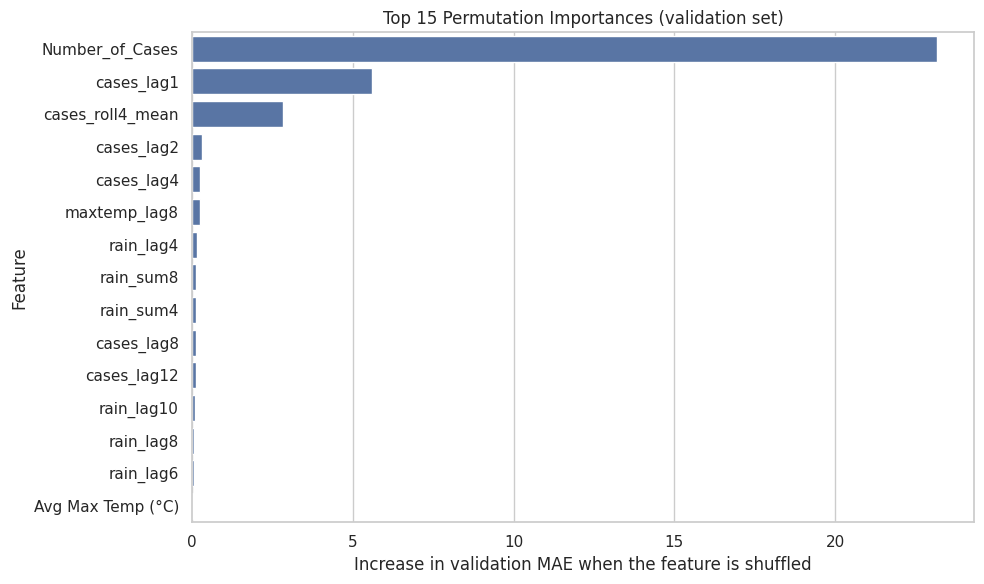

In [ ]:
from sklearn.inspection import permutation_importance

# Permutation importance on the validation set
perm = permutation_importance(
    rf_best, X_val, y_val,
    scoring="neg_mean_absolute_error",
    n_repeats=5, random_state=42, n_jobs=-1
)

perm_importance = pd.DataFrame({
    "Feature": feature_cols,
    "MAE increase": perm.importances_mean,
    "Std": perm.importances_std
}).sort_values("MAE increase", ascending=False)

print("Top 15 features by permutation importance:")
display(perm_importance.head(15).round(3))

plt.figure(figsize=(10, 6))
sns.barplot(data=perm_importance.head(15), x="MAE increase", y="Feature")
plt.title("Top 15 Permutation Importances (validation set)")
plt.xlabel("Increase in validation MAE when the feature is shuffled")
plt.tight_layout()
plt.show()

In [ ]:
display(pd.DataFrame(results).round(3))

,Model,Dataset,MAE,RMSE,R2
0,Naive,Validation,10.787,27.025,0.880
1,Naive,Test,13.571,27.419,0.920
2,Linear Regression,Validation,11.101,26.543,0.884
3,Linear Regression,Test,13.200,25.870,0.929
4,Random Forest (initial),Validation,10.633,26.031,0.889
5,Random Forest (Tuned),Validation,10.573,25.618,0.892
6,Random Forest (Tuned),Test,13.821,28.191,0.915


In [ ]:
# Is the test period outside the range seen in training?
print("Training target:   max =", y_train.max(), "| 99th percentile =", round(y_train.quantile(0.99), 1))
print("Validation target: max =", y_val.max())
print("Test target:       max =", y_test.max(), "| 99th percentile =", round(y_test.quantile(0.99), 1))
print("Share of test rows with target above the training maximum: {:.2%}".format((y_test > y_train.max()).mean()))
print("Share of test rows with target above the training 99th percentile: {:.2%}".format(
    (y_test > y_train.quantile(0.99)).mean()))

# Error of Naive vs Random Forest, split into low-case and high-case rows (test set)
test_eval = pd.DataFrame({
    "actual": y_test.values,
    "naive": test_df["Number_of_Cases"].values,
    "rf": rf_best_test_pred
})
test_eval["group"] = pd.cut(test_eval["actual"], bins=[-1, 20, 100, 10000],
                            labels=["low (<=20)", "medium (21-100)", "high (>100)"])
summary = test_eval.groupby("group").apply(lambda d: pd.Series({
    "rows": len(d),
    "Naive MAE": mean_absolute_error(d["actual"], d["naive"]),
    "RF MAE": mean_absolute_error(d["actual"], d["rf"]),
    "RF mean prediction": d["rf"].mean(),
    "Actual mean": d["actual"].mean()
}))
display(summary.round(2))

Training target:   max = 2631.0 | 99th percentile = 386.8
Validation target: max = 1004.0
Test target:       max = 707.0 | 99th percentile = 478.0
Share of test rows with target above the training maximum: 0.00%
Share of test rows with target above the training 99th percentile: 2.55%


,rows,Naive MAE,RF MAE,RF mean prediction,Actual mean
group,,,,,
low (<=20),912.0,4.18,4.42,10.78,7.93
medium (21-100),787.0,13.36,12.86,53.03,49.92
high (>100),301.0,42.57,44.84,234.33,240.02


**Random Forest Summary:** The tuned Random Forest achieved an MAE of 10.57, an RMSE of 25.62 and an R² of 0.892 on the validation set, and an MAE of 13.82, an RMSE of 28.19 and an R² of 0.915 on the test set (training MAE 5.66). On the test set it is marginally worse than the Naive Forecast (MAE 13.57, RMSE 27.42) and Linear Regression (MAE 13.20, RMSE 25.87), so it cannot be said to outperform the baselines.

Both impurity-based and permutation importance show that the predictions are driven almost entirely by recent case counts: shuffling the current week's cases raises the validation MAE by 23.16, the previous week's cases by 5.59 and the 4-week rolling mean by 2.84, whereas every weather feature raises it by less than 0.25 (for example, the 8-week lagged maximum temperature 0.24, rainfall lagged by 4 weeks 0.17 and the 8-week rolling rainfall total 0.13). Weather features therefore add a small but consistent contribution.

The test period has higher dengue activity than the training period (59.4 vs 32.1 mean next-week cases), but all test targets lie within the training range (maximum 707 vs 2,631), so the weaker test result is not due to values outside that range. The Random Forest has a lower MAE than the Naive Forecast for medium case counts (12.86 vs 13.36) but a higher MAE for low (4.42 vs 4.18) and high counts above 100 (44.84 vs 42.57); the 301 high-case rows (15% of the test set) account for about half of the total error of both models. Overall, the Random Forest and the Naive Forecast perform very similarly, and the differences are too small to conclude that either is clearly better.

## Helper function - Avoid duplicate rows

In [ ]:
def evaluate_model(model_name, dataset_name, y_true, y_pred):
    """Calculate MAE, RMSE and R2; replaces an existing row for the same model and dataset."""
    global results
    results = [r for r in results if not (r["Model"] == model_name and r["Dataset"] == dataset_name)]
    results.append({
        "Model": model_name,
        "Dataset": dataset_name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    })

## 12. Boosting Ensemble Models

This section evaluates three boosting-based ensemble learning algorithms: XGBoost, LightGBM and CatBoost. T

### 12.1 XGBoost



In [ ]:
from xgboost import XGBRegressor
import time

# 1. Define hyperparameter configurations
xgb_configs = [
    {
        "max_depth": 4,
        "learning_rate": 0.05,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "min_child_weight": 5
    },
    {
        "max_depth": 6,
        "learning_rate": 0.05,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "min_child_weight": 5
    },
    {
        "max_depth": 6,
        "learning_rate": 0.03,
        "subsample": 0.7,
        "colsample_bytree": 0.7,
        "min_child_weight": 10
    }
]

# 2. Train and validate each configuration
xgb_rows = []
xgb_models = []

for i, params in enumerate(xgb_configs, start=1):

    start = time.time()

    model = XGBRegressor(
        n_estimators=2000,
        early_stopping_rounds=50,
        eval_metric="mae",
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1,
        **params
    )

    model.fit(
        X_train,
        y_train,
        eval_set=[(X_val, y_val)],
        verbose=False
    )

    n_trees = model.best_iteration + 1

    train_pred = model.predict(
        X_train, iteration_range=(0, n_trees)
    )

    val_pred = model.predict(
        X_val, iteration_range=(0, n_trees)
    )

    xgb_models.append(model)

    xgb_rows.append({
        "Configuration": i,
        "Trees used": n_trees,
        "Train_MAE": mean_absolute_error(y_train, train_pred),
        "Val_MAE": mean_absolute_error(y_val, val_pred),
        "Val_RMSE": np.sqrt(mean_squared_error(y_val, val_pred)),
        "Val_R2": r2_score(y_val, val_pred),
        "Time_sec": round(time.time() - start, 1)
    })

    print(f"Configuration {i} completed")

# 3. Compare configurations
xgb_tuning_df = pd.DataFrame(xgb_rows)

display(
    xgb_tuning_df.sort_values("Val_MAE").round(3)
)

# 4. Select best configuration using validation MAE
best_i = int(
    xgb_tuning_df.sort_values("Val_MAE")
    .iloc[0]["Configuration"]
)

xgb_best = xgb_models[best_i - 1]
n_trees = xgb_best.best_iteration + 1

print("\nBest XGBoost Configuration:", best_i)
print("Parameters:", xgb_configs[best_i - 1])
print("Best number of trees:", n_trees)

# 5. Final predictions
xgb_train_pred = xgb_best.predict(
    X_train, iteration_range=(0, n_trees)
)

xgb_val_pred = xgb_best.predict(
    X_val, iteration_range=(0, n_trees)
)

xgb_test_pred = xgb_best.predict(
    X_test, iteration_range=(0, n_trees)
)

# 6. Evaluate final performance
for name, actual, pred in [
    ("Training", y_train, xgb_train_pred),
    ("Validation", y_val, xgb_val_pred),
    ("Test", y_test, xgb_test_pred)
]:

    print(
        f"{name:10s} "
        f"MAE={mean_absolute_error(actual, pred):.3f}  "
        f"RMSE={np.sqrt(mean_squared_error(actual, pred)):.3f}  "
        f"R2={r2_score(actual, pred):.3f}"
    )

# 7. Save validation and test results
evaluate_model(
    "XGBoost (Tuned)", "Validation", y_val, xgb_val_pred
)

evaluate_model(
    "XGBoost (Tuned)", "Test", y_test, xgb_test_pred
)

Configuration 1 completed
Configuration 2 completed
Configuration 3 completed


,Configuration,Trees used,Train_MAE,Val_MAE,Val_RMSE,Val_R2,Time_sec
0,1,75,9.359,11.471,31.098,0.841,0.6
1,2,75,8.147,11.495,31.204,0.840,1.0
2,3,142,8.340,11.628,33.229,0.818,1.2



Best XGBoost Configuration: 1
Parameters: {'max_depth': 4, 'learning_rate': 0.05, 'subsample': 0.8, 'colsample_bytree': 0.8, 'min_child_weight': 5}
Best number of trees: 75
Training   MAE=9.359  RMSE=21.897  R2=0.938
Validation MAE=11.471  RMSE=31.098  R2=0.841
Test       MAE=14.002  RMSE=29.432  R2=0.908


## 12.2 LightGBM

In [ ]:
import lightgbm as lgb
from lightgbm import LGBMRegressor

lgbm_configs = [
    {"num_leaves": 15, "learning_rate": 0.05, "min_child_samples": 20, "subsample": 0.8, "colsample_bytree": 0.8},
    {"num_leaves": 31, "learning_rate": 0.05, "min_child_samples": 20, "subsample": 0.8, "colsample_bytree": 0.8},
    {"num_leaves": 63, "learning_rate": 0.03, "min_child_samples": 40, "subsample": 0.7, "colsample_bytree": 0.7},
]

lgbm_rows, lgbm_models = [], []
for i, params in enumerate(lgbm_configs, start=1):
    start = time.time()
    model = LGBMRegressor(n_estimators=2000, subsample_freq=1, random_state=42, n_jobs=-1, verbose=-1, **params)
    model.fit(X_train, y_train, eval_set=[(X_val, y_val)], eval_metric="l1",
              callbacks=[lgb.early_stopping(50, verbose=False)])

    n_trees = model.best_iteration_
    val_pred = model.predict(X_val, num_iteration=n_trees)
    lgbm_models.append(model)
    lgbm_rows.append({
        "Configuration": i, "Trees used": n_trees,
        "Train_MAE": mean_absolute_error(y_train, model.predict(X_train, num_iteration=n_trees)),
        "Val_MAE": mean_absolute_error(y_val, val_pred),
        "Val_RMSE": np.sqrt(mean_squared_error(y_val, val_pred)),
        "Val_R2": r2_score(y_val, val_pred),
        "Time_sec": round(time.time() - start, 1),
    })
    print(f"LightGBM configuration {i} done ({lgbm_rows[-1]['Time_sec']} s, {n_trees} trees)")

lgbm_tuning_df = pd.DataFrame(lgbm_rows)
display(lgbm_tuning_df.sort_values("Val_MAE").round(3))

best_i = int(lgbm_tuning_df.sort_values("Val_MAE").iloc[0]["Configuration"])
lgbm_best = lgbm_models[best_i - 1]
n_trees = lgbm_best.best_iteration_
print("Best LightGBM configuration:", best_i, lgbm_configs[best_i - 1], "| trees:", n_trees)

lgbm_train_pred = lgbm_best.predict(X_train, num_iteration=n_trees)
lgbm_val_pred   = lgbm_best.predict(X_val,   num_iteration=n_trees)
lgbm_test_pred  = lgbm_best.predict(X_test,  num_iteration=n_trees)

for name, actual, pred in [("Training", y_train, lgbm_train_pred), ("Validation", y_val, lgbm_val_pred), ("Test", y_test, lgbm_test_pred)]:
    print(f"{name:10s} MAE={mean_absolute_error(actual, pred):.3f}  RMSE={np.sqrt(mean_squared_error(actual, pred)):.3f}  R2={r2_score(actual, pred):.3f}")

evaluate_model("LightGBM (Tuned)", "Validation", y_val,  lgbm_val_pred)
evaluate_model("LightGBM (Tuned)", "Test",       y_test, lgbm_test_pred)

LightGBM configuration 1 done (0.6 s, 111 trees)
LightGBM configuration 2 done (2.7 s, 100 trees)
LightGBM configuration 3 done (1.7 s, 105 trees)


,Configuration,Trees used,Train_MAE,Val_MAE,Val_RMSE,Val_R2,Time_sec
1,2,100,8.403,10.876,26.655,0.883,2.7
0,1,111,9.059,10.888,27.119,0.879,0.6
2,3,105,9.281,11.368,27.643,0.874,1.7


Best LightGBM configuration: 2 {'num_leaves': 31, 'learning_rate': 0.05, 'min_child_samples': 20, 'subsample': 0.8, 'colsample_bytree': 0.8} | trees: 100
Training   MAE=8.403  RMSE=23.295  R2=0.930
Validation MAE=10.876  RMSE=26.655  R2=0.883
Test       MAE=14.213  RMSE=28.726  R2=0.912


## 12.3 CatBoost

In [ ]:
from catboost import CatBoostRegressor

cat_configs = [
    {"depth": 4, "learning_rate": 0.05, "l2_leaf_reg": 3},
    {"depth": 6, "learning_rate": 0.05, "l2_leaf_reg": 3},
    {"depth": 8, "learning_rate": 0.03, "l2_leaf_reg": 5},
]

cat_rows, cat_models = [], []
for i, params in enumerate(cat_configs, start=1):
    start = time.time()
    model = CatBoostRegressor(iterations=2000, eval_metric="MAE", early_stopping_rounds=50,
                              use_best_model=True, random_seed=42, verbose=False, thread_count=-1, **params)
    model.fit(X_train, y_train, eval_set=(X_val, y_val))

    n_trees = model.get_best_iteration() + 1
    val_pred = model.predict(X_val)
    cat_models.append(model)
    cat_rows.append({
        "Configuration": i, "Trees used": n_trees,
        "Train_MAE": mean_absolute_error(y_train, model.predict(X_train)),
        "Val_MAE": mean_absolute_error(y_val, val_pred),
        "Val_RMSE": np.sqrt(mean_squared_error(y_val, val_pred)),
        "Val_R2": r2_score(y_val, val_pred),
        "Time_sec": round(time.time() - start, 1),
    })
    print(f"CatBoost configuration {i} done ({cat_rows[-1]['Time_sec']} s, {n_trees} trees)")

cat_tuning_df = pd.DataFrame(cat_rows)
display(cat_tuning_df.sort_values("Val_MAE").round(3))

best_i = int(cat_tuning_df.sort_values("Val_MAE").iloc[0]["Configuration"])
cat_best = cat_models[best_i - 1]
print("Best CatBoost configuration:", best_i, cat_configs[best_i - 1], "| trees:", cat_best.get_best_iteration() + 1)

cat_train_pred = cat_best.predict(X_train)
cat_val_pred   = cat_best.predict(X_val)
cat_test_pred  = cat_best.predict(X_test)

for name, actual, pred in [("Training", y_train, cat_train_pred), ("Validation", y_val, cat_val_pred), ("Test", y_test, cat_test_pred)]:
    print(f"{name:10s} MAE={mean_absolute_error(actual, pred):.3f}  RMSE={np.sqrt(mean_squared_error(actual, pred)):.3f}  R2={r2_score(actual, pred):.3f}")

evaluate_model("CatBoost (Tuned)", "Validation", y_val,  cat_val_pred)
evaluate_model("CatBoost (Tuned)", "Test",       y_test, cat_test_pred)

CatBoost configuration 1 done (1.6 s, 250 trees)
CatBoost configuration 2 done (2.7 s, 251 trees)
CatBoost configuration 3 done (13.0 s, 443 trees)


,Configuration,Trees used,Train_MAE,Val_MAE,Val_RMSE,Val_R2,Time_sec
0,1,250,9.210,10.889,27.380,0.877,1.6
1,2,251,8.719,10.890,27.896,0.872,2.7
2,3,443,8.444,10.961,27.915,0.872,13.0


Best CatBoost configuration: 1 {'depth': 4, 'learning_rate': 0.05, 'l2_leaf_reg': 3} | trees: 250
Training   MAE=9.210  RMSE=20.692  R2=0.945
Validation MAE=10.889  RMSE=27.380  R2=0.877
Test       MAE=14.069  RMSE=28.851  R2=0.911


## 12.4 Comparison



MAE


Dataset,Validation,Test
Model,,
Naive,10.787,13.571
Linear Regression,11.101,13.200
Random Forest (Tuned),10.573,13.821
XGBoost (Tuned),11.471,14.002
LightGBM (Tuned),10.876,14.213
CatBoost (Tuned),10.889,14.069



RMSE


Dataset,Validation,Test
Model,,
Naive,27.025,27.419
Linear Regression,26.543,25.870
Random Forest (Tuned),25.618,28.191
XGBoost (Tuned),31.098,29.432
LightGBM (Tuned),26.655,28.726
CatBoost (Tuned),27.380,28.851



R2


Dataset,Validation,Test
Model,,
Naive,0.880,0.920
Linear Regression,0.884,0.929
Random Forest (Tuned),0.892,0.915
XGBoost (Tuned),0.841,0.908
LightGBM (Tuned),0.883,0.912
CatBoost (Tuned),0.877,0.911


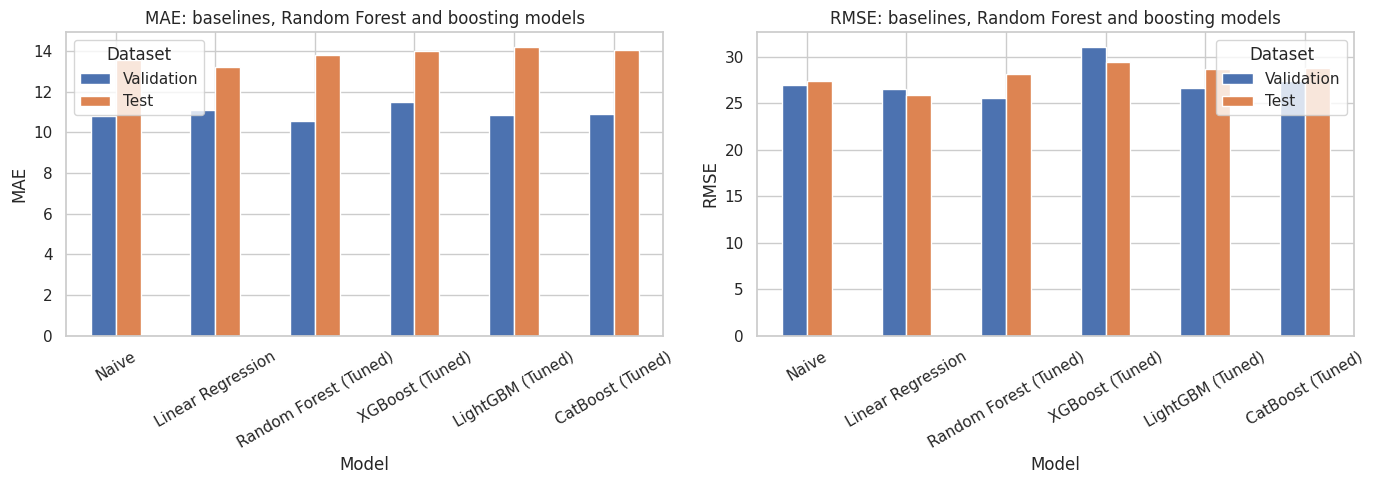

In [ ]:
comparison_models = ["Naive", "Linear Regression", "Random Forest (Tuned)",
                     "XGBoost (Tuned)", "LightGBM (Tuned)", "CatBoost (Tuned)"]
res = pd.DataFrame(results)
res = res[res["Model"].isin(comparison_models)]

for metric in ["MAE", "RMSE", "R2"]:
    print(f"\n{metric}")
    display(res.pivot(index="Model", columns="Dataset", values=metric)
               .reindex(comparison_models)[["Validation", "Test"]].round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, metric in zip(ax, ["MAE", "RMSE"]):
    res.pivot(index="Model", columns="Dataset", values=metric).reindex(comparison_models)[["Validation", "Test"]] \
       .plot.bar(ax=a, rot=30)
    a.set_title(f"{metric}: baselines, Random Forest and boosting models"); a.set_ylabel(metric)
plt.tight_layout(); plt.show()

## 13. Stacking Ensemble

Stacking combines the predictions of several base models through a meta-learner. The base models are the tuned Random Forest, XGBoost, LightGBM and CatBoost, and the meta-learner is a Ridge regression (non-negative coefficients, alpha = 1) that learns how much weight to give each base model.

To avoid leakage, the meta-learner is trained only on out-of-fold predictions generated inside the training period. The training weeks are split chronologically into six blocks (splitting by week so that all districts of the same week stay together); for each of the last five blocks, the base models are trained on all earlier blocks and predict that block. The meta-learner is fitted on these predictions, so the first block has no out-of-fold predictions and is not used for the meta-learner. The validation and test sets are not used to fit the meta-learner. For the final predictions, the base models already trained on the full training set are used, and their predictions on the validation and test sets are combined by the meta-learner. The numbers of trees of the boosting models were taken from the earlier early-stopping runs, which used the validation set, so the validation figures may be slightly optimistic.

In [ ]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit
import xgboost as xgb_lib, lightgbm as lgb_lib, catboost as cb_lib

# Base models with the best settings found earlier (number of trees fixed from early stopping)
base_factories = {
    "Random Forest": lambda: RandomForestRegressor(
        n_estimators=400, max_depth=15, min_samples_leaf=3, max_features=0.7,
        random_state=42, n_jobs=-1),
    "XGBoost": lambda: xgb_lib.XGBRegressor(
        n_estimators=75, max_depth=4, learning_rate=0.05, subsample=0.8,
        colsample_bytree=0.8, min_child_weight=5, random_state=42, n_jobs=-1),
    "LightGBM": lambda: lgb_lib.LGBMRegressor(
        n_estimators=100, num_leaves=31, learning_rate=0.05, min_child_samples=20,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
        random_state=42, n_jobs=-1, verbose=-1),
    "CatBoost": lambda: cb_lib.CatBoostRegressor(
        iterations=250, depth=4, learning_rate=0.05, l2_leaf_reg=3,
        random_seed=42, verbose=False, thread_count=-1),
}
base_names = list(base_factories.keys())

# Chronological out-of-fold predictions inside the training period (split by WEEK)
weeks = np.sort(train_df["Week_Start_Date"].unique())
row_week = train_df["Week_Start_Date"].values
oof = np.full((len(train_df), len(base_names)), np.nan)

start = time.time()
for k, (train_w, valid_w) in enumerate(TimeSeriesSplit(n_splits=5).split(weeks), start=1):
    tr_idx = np.where(np.isin(row_week, weeks[train_w]))[0]
    va_idx = np.where(np.isin(row_week, weeks[valid_w]))[0]
    for j, name in enumerate(base_names):
        model = base_factories[name]()
        model.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
        oof[va_idx, j] = model.predict(X_train.iloc[va_idx])
    print(f"Fold {k} done: trained on {len(tr_idx)} rows, predicted {len(va_idx)} rows ({time.time() - start:.0f} s)")

# Meta-learner trained on out-of-fold predictions only
has_oof = ~np.isnan(oof).any(axis=1)
print("Rows used to train the meta-learner:", has_oof.sum(), "of", len(oof))

meta = Ridge(alpha=1.0, positive=True)
meta.fit(oof[has_oof], y_train.values[has_oof])
print("\nMeta-learner weights:")
display(pd.DataFrame({"Base model": base_names, "Weight": meta.coef_}).round(3))
print("Intercept:", round(meta.intercept_, 3))

# Final predictions: base models already trained on the full training set
stack_val_base = np.column_stack([rf_best_val_pred, xgb_val_pred, lgbm_val_pred, cat_val_pred])
stack_test_base = np.column_stack([rf_best_test_pred, xgb_test_pred, lgbm_test_pred, cat_test_pred])

stack_val_pred = np.clip(meta.predict(stack_val_base), 0, None)
stack_test_pred = np.clip(meta.predict(stack_test_base), 0, None)

for name, actual, pred in [("Validation", y_val, stack_val_pred), ("Test", y_test, stack_test_pred)]:
    print(f"{name:10s} MAE={mean_absolute_error(actual, pred):.3f}  RMSE={np.sqrt(mean_squared_error(actual, pred)):.3f}  R2={r2_score(actual, pred):.3f}")

evaluate_model("Stacking", "Validation", y_val,  stack_val_pred)
evaluate_model("Stacking", "Test",       y_test, stack_test_pred)
display(pd.DataFrame(results).round(3))

Fold 1 done: trained on 3100 rows, predicted 2975 rows (14 s)
Fold 2 done: trained on 6075 rows, predicted 2975 rows (42 s)
Fold 3 done: trained on 9050 rows, predicted 2975 rows (84 s)
Fold 4 done: trained on 12025 rows, predicted 2975 rows (141 s)
Fold 5 done: trained on 15000 rows, predicted 2975 rows (213 s)
Rows used to train the meta-learner: 14875 of 17975

Meta-learner weights:


,Base model,Weight
0,Random Forest,0.459
1,XGBoost,0.000
2,LightGBM,0.000
3,CatBoost,0.835


Intercept: -5.563
Validation MAE=14.003  RMSE=35.941  R2=0.787
Test       MAE=21.214  RMSE=45.333  R2=0.781


,Model,Dataset,MAE,RMSE,R2
0,Naive,Validation,10.787,27.025,0.880
1,Naive,Test,13.571,27.419,0.920
2,Linear Regression,Validation,11.101,26.543,0.884
3,Linear Regression,Test,13.200,25.870,0.929
4,Random Forest (initial),Validation,10.633,26.031,0.889
5,Random Forest (Tuned),Validation,10.573,25.618,0.892
6,Random Forest (Tuned),Test,13.821,28.191,0.915
7,XGBoost (Tuned),Validation,11.471,31.098,0.841
8,XGBoost (Tuned),Test,14.002,29.432,0.908
9,LightGBM (Tuned),Validation,10.876,26.655,0.883


In [ ]:
import itertools

# ---------- Part A: why did the Ridge stacking perform badly? ----------
y_oof  = y_train.values[has_oof]
oof_ok = oof[has_oof]

# Fold id of each training row
fold_id = np.zeros(len(train_df), dtype=int)
for k, (train_w, valid_w) in enumerate(TimeSeriesSplit(n_splits=5).split(weeks), start=1):
    fold_id[np.isin(row_week, weeks[valid_w])] = k

# 1. Do the base models under-predict inside the out-of-fold period?
#    ratio = total actual / total predicted (above 1 means under-prediction)
rows = []
for j, name in enumerate(base_names):
    rows.append({
        "Base model": name,
        "OOF MAE": mean_absolute_error(y_oof, oof_ok[:, j]),
        "OOF actual/pred ratio": y_oof.sum() / oof_ok[:, j].sum(),
        "Val MAE": mean_absolute_error(y_val, stack_val_base[:, j]),
        "Val actual/pred ratio": y_val.values.sum() / stack_val_base[:, j].sum(),
    })
print("Scale check of the base models:")
display(pd.DataFrame(rows).round(3))

# 2. Which out-of-fold block contains the largest cases and the largest under-prediction?
avg_oof = oof.mean(axis=1)
fold_rows = []
for k in range(1, 6):
    m = fold_id == k
    fold_rows.append({
        "Fold": k,
        "From": str(pd.Timestamp(row_week[m].min()).date()),
        "To": str(pd.Timestamp(row_week[m].max()).date()),
        "Mean actual": y_train.values[m].mean(),
        "Mean predicted (avg of 4)": avg_oof[m].mean(),
        "Max actual": y_train.values[m].max(),
    })
print("\nOut-of-fold blocks:")
display(pd.DataFrame(fold_rows).round(1))

# 3. Effect of the Ridge meta-learner on the overall scale
print("\nTotal predicted / total actual for the Ridge stacking:")
print("  on the out-of-fold rows it was fitted on:", round(meta.predict(oof_ok).sum() / y_oof.sum(), 3))
print("  on the validation set:                   ", round(stack_val_pred.sum() / y_val.values.sum(), 3))

# ---------- Part B: stacking with convex weights (non-negative, sum to 1, no intercept) ----------
step = 20            # weights in steps of 1/20 = 0.05
best_mae, best_w = None, None
for a in range(step + 1):
    for b in range(step + 1 - a):
        for c in range(step + 1 - a - b):
            d = step - a - b - c
            w = np.array([a, b, c, d]) / step
            mae = mean_absolute_error(y_oof, oof_ok @ w)
            if best_mae is None or mae < best_mae:
                best_mae, best_w = mae, w

print("\nConvex stacking weights (chosen on out-of-fold MAE only):")
display(pd.DataFrame({"Base model": base_names, "Weight": best_w}).round(2))

stack2_val_pred  = stack_val_base  @ best_w
stack2_test_pred = stack_test_base @ best_w

# ---------- Part C: store the results ----------
results = [r for r in results if r["Model"] != "Stacking"]
evaluate_model("Stacking (Ridge, unconstrained)", "Validation", y_val,  stack_val_pred)
evaluate_model("Stacking (Ridge, unconstrained)", "Test",       y_test, stack_test_pred)
evaluate_model("Stacking (convex weights)",       "Validation", y_val,  stack2_val_pred)
evaluate_model("Stacking (convex weights)",       "Test",       y_test, stack2_test_pred)

print("\nEqual-weight average of the four base models (for reference, nothing fitted):")
for name, actual, pred in [("Validation", y_val, stack_val_base.mean(axis=1)), ("Test", y_test, stack_test_base.mean(axis=1))]:
    print(f"  {name:10s} MAE={mean_absolute_error(actual, pred):.3f}  RMSE={np.sqrt(mean_squared_error(actual, pred)):.3f}")

display(pd.DataFrame(results).round(3))

Scale check of the base models:


,Base model,OOF MAE,OOF actual/pred ratio,Val MAE,Val actual/pred ratio
0,Random Forest,13.575,1.112,10.573,1.014
1,XGBoost,14.122,1.146,11.471,1.001
2,LightGBM,14.005,1.131,10.876,1.022
3,CatBoost,13.640,1.131,10.889,1.012



Out-of-fold blocks:


,Fold,From,To,Mean actual,Mean predicted (avg of 4),Max actual
0,1,2009-08-10,2011-11-14,17.3,18.2,475.0
1,2,2011-11-21,2014-02-24,18.2,17.9,338.0
2,3,2014-03-03,2016-06-06,22.5,21.3,491.0
3,4,2016-06-13,2018-09-17,79.0,59.6,2631.0
4,5,2018-09-24,2020-12-28,47.2,46.1,931.0



Total predicted / total actual for the Ridge stacking:
  on the out-of-fold rows it was fitted on: 1.0
  on the validation set:                    1.15

Convex stacking weights (chosen on out-of-fold MAE only):


,Base model,Weight
0,Random Forest,0.6
1,XGBoost,0.0
2,LightGBM,0.0
3,CatBoost,0.4



Equal-weight average of the four base models (for reference, nothing fitted):
  Validation MAE=10.694  RMSE=26.635
  Test       MAE=13.738  RMSE=27.863


,Model,Dataset,MAE,RMSE,R2
0,Naive,Validation,10.787,27.025,0.880
1,Naive,Test,13.571,27.419,0.920
2,Linear Regression,Validation,11.101,26.543,0.884
3,Linear Regression,Test,13.200,25.870,0.929
4,Random Forest (initial),Validation,10.633,26.031,0.889
5,Random Forest (Tuned),Validation,10.573,25.618,0.892
6,Random Forest (Tuned),Test,13.821,28.191,0.915
7,XGBoost (Tuned),Validation,11.471,31.098,0.841
8,XGBoost (Tuned),Test,14.002,29.432,0.908
9,LightGBM (Tuned),Validation,10.876,26.655,0.883


In [ ]:
# Diagnostics: out-of-fold (OOF) predictions versus validation predictions
oof_actual = y_train.values[has_oof]

print("OOF prediction statistics:")
display(pd.DataFrame(oof[has_oof], columns=base_names).describe().round(2))

print("\nValidation base prediction statistics:")
display(pd.DataFrame(stack_val_base, columns=base_names).describe().round(2))

# OOF and validation performance of the base models
oof_results = []
for i, name in enumerate(base_names):
    pred = oof[has_oof, i]
    oof_results.append({"Model": name,
                        "OOF MAE": mean_absolute_error(oof_actual, pred),
                        "OOF RMSE": np.sqrt(mean_squared_error(oof_actual, pred)),
                        "OOF R2": r2_score(oof_actual, pred)})
print("\nOOF base model performance:")
display(pd.DataFrame(oof_results).round(3))

val_base_results = []
for i, name in enumerate(base_names):
    pred = stack_val_base[:, i]
    val_base_results.append({"Model": name,
                             "Validation MAE": mean_absolute_error(y_val, pred),
                             "Validation RMSE": np.sqrt(mean_squared_error(y_val, pred)),
                             "Validation R2": r2_score(y_val, pred)})
print("\nValidation base model performance:")
display(pd.DataFrame(val_base_results).round(3))

# Similarity of the base models
print("\nCorrelation between OOF base predictions:")
display(pd.DataFrame(oof[has_oof], columns=base_names).corr().round(3))

oof_residuals = pd.DataFrame(oof_actual[:, None] - oof[has_oof], columns=base_names)
print("\nCorrelation between OOF residuals:")
display(oof_residuals.corr().round(3))

OOF prediction statistics:


,Random Forest,XGBoost,LightGBM,CatBoost
count,14875.00,14875.00,14875.00,14875.00
mean,33.14,32.17,32.59,32.58
std,61.18,61.62,60.62,60.69
min,0.00,0.66,-1.09,-0.23
25%,4.55,4.58,4.39,4.12
50%,11.55,11.47,11.38,11.08
75%,33.31,31.51,32.27,31.85
max,924.81,1338.17,1151.34,916.54



Validation base prediction statistics:


,Random Forest,XGBoost,LightGBM,CatBoost
count,2600.00,2600.00,2600.00,2600.00
mean,37.46,37.95,37.18,37.55
std,74.15,81.49,73.43,76.30
min,0.09,1.98,1.14,0.17
25%,3.76,4.58,3.85,4.18
50%,12.10,12.61,12.07,12.34
75%,39.77,39.14,38.46,38.99
max,986.27,1247.03,1127.86,1322.50



OOF base model performance:


,Model,OOF MAE,OOF RMSE,OOF R2
0,Random Forest,13.575,57.160,0.642
1,XGBoost,14.122,59.701,0.609
2,LightGBM,14.005,57.996,0.631
3,CatBoost,13.640,57.062,0.643


... (2 outputs left out)


Correlation between OOF base predictions:


,Random Forest,XGBoost,LightGBM,CatBoost
Random Forest,1.000,0.980,0.992,0.995
XGBoost,0.980,1.000,0.974,0.978
LightGBM,0.992,0.974,1.000,0.990
CatBoost,0.995,0.978,0.990,1.000



Correlation between OOF residuals:


,Random Forest,XGBoost,LightGBM,CatBoost
Random Forest,1.000,0.979,0.991,0.994
XGBoost,0.979,1.000,0.972,0.977
LightGBM,0.991,0.972,1.000,0.989
CatBoost,0.994,0.977,0.989,1.000


## Stacking Results

I combined four models (Random Forest, XGBoost, LightGBM and CatBoost) using a Ridge model, which learns how much to trust each one. The result was worse than every single model: the test MAE was 21.21, compared with 13.82 for the Random Forest.

**Why it went wrong.** The Ridge model learns from predictions that the four models make on data they have not seen, taken from inside the training period. In 2016–2018, which includes the big 2017 outbreak, the models predicted too low (average actual cases 79.0, average predicted 59.6). The Ridge model tried to fix this by pushing predictions up (its weights added up to 1.29 and the intercept was −5.56). On the validation data the models were already about right, so this push made the total predicted cases about 15% too high.

The four models also give almost the same predictions (correlation above 0.97), so combining them adds very little.

**Fix.** I tried a second version where the weights must be positive, add up to 1, and have no intercept, so the predictions cannot be scaled up or down. The weights were chosen using the training period only: 0.6 for Random Forest and 0.4 for CatBoost. This gave a test MAE of 13.76, which is much better than the first version, but about the same as the Random Forest (13.82) and a simple average of the four models (13.74). So stacking did not really improve the results. The Naive forecast (13.57) is still slightly better on the test set.

I made the second version after seeing the test result of the first one, so both are reported.

## 14. ARIMA and Hybrid ARIMA + Random Forest

**ARIMA.** A separate ARIMA model is fitted to the weekly case series of each of the 25 districts. The parameters are estimated using data up to 2020-12-28 only (the training period) and are then kept fixed; one-step-ahead predictions for all later weeks are obtained from the observed past cases without refitting. Three candidate orders are compared on the validation set and the one with the lowest validation MAE is selected.

**Hybrid ARIMA + Random Forest.** The ARIMA model captures the linear temporal structure of the series, and a Random Forest is trained on the ARIMA residuals (actual minus ARIMA prediction) using the engineered features plus the ARIMA prediction. The hybrid prediction is the ARIMA prediction plus the residual predicted by the Random Forest. Both components are fitted on the training period only. The ARIMA residuals on the training period are in-sample, because the ARIMA parameters were estimated on the same period, which is a limitation of this procedure.

##14.1: ARIMA

In [ ]:
from statsmodels.tsa.arima.model import ARIMA
import warnings
warnings.filterwarnings("ignore")

TRAIN_END = pd.Timestamp("2020-12-28")      # last week of the training period

def arima_one_step(order):
    """One-step-ahead ARIMA predictions for every week of every district.
    Parameters are estimated on data up to TRAIN_END only, then applied to the whole series."""
    parts = []
    for district, g in df.sort_values(["District", "Week_Start_Date"]).groupby("District"):
        y = g["Number_of_Cases"].values.astype(float)
        n_train = int((g["Week_Start_Date"] <= TRAIN_END).sum())
        try:
            fitted_model = ARIMA(y[:n_train], order=order).fit()
            fitted = np.asarray(fitted_model.apply(y, refit=False).fittedvalues, dtype=float)
        except Exception:
            fitted = np.r_[y[0], y[:-1]]                # fallback: naive prediction
        parts.append(pd.DataFrame({
            "District": district,
            "Target_Week": g["Week_Start_Date"].values,
            "arima_pred": np.clip(fitted, 0, None),
        }))
    return pd.concat(parts, ignore_index=True)

def arima_for_rows(frame, arima_table):
    """ARIMA prediction for the target week (feature week + 7 days) of each row."""
    f = frame[["District", "Week_Start_Date"]].copy()
    f["Target_Week"] = f["Week_Start_Date"] + pd.Timedelta(days=7)
    merged = f.merge(arima_table, on=["District", "Target_Week"], how="left")
    return merged["arima_pred"].values

# Compare candidate orders on the validation set
candidate_orders = [(1, 0, 0), (2, 0, 1), (1, 1, 1)]
arima_tables, arima_rows = {}, []
for order in candidate_orders:
    start = time.time()
    table = arima_one_step(order)
    arima_tables[order] = table
    val_arima = arima_for_rows(val_df, table)
    arima_rows.append({"Order": str(order),
                       "Val_MAE": mean_absolute_error(y_val, val_arima),
                       "Val_RMSE": np.sqrt(mean_squared_error(y_val, val_arima)),
                       "Val_R2": r2_score(y_val, val_arima),
                       "NaN predictions": int(np.isnan(val_arima).sum()),
                       "Time_sec": round(time.time() - start, 1)})
    print(f"ARIMA{order} done ({arima_rows[-1]['Time_sec']} s)")

arima_df = pd.DataFrame(arima_rows)
display(arima_df.sort_values("Val_MAE").round(3))

best_order = candidate_orders[int(arima_df["Val_MAE"].idxmin())]
arima_table = arima_tables[best_order]
print("Selected ARIMA order:", best_order)

arima_train_pred = arima_for_rows(train_df, arima_table)
arima_val_pred   = arima_for_rows(val_df,   arima_table)
arima_test_pred  = arima_for_rows(test_df,  arima_table)

for name, actual, pred in [("Training (in-sample)", y_train, arima_train_pred),
                           ("Validation", y_val, arima_val_pred), ("Test", y_test, arima_test_pred)]:
    print(f"{name:22s} MAE={mean_absolute_error(actual, pred):.3f}  RMSE={np.sqrt(mean_squared_error(actual, pred)):.3f}  R2={r2_score(actual, pred):.3f}")

evaluate_model("ARIMA", "Validation", y_val,  arima_val_pred)
evaluate_model("ARIMA", "Test",       y_test, arima_test_pred)

ARIMA(1, 0, 0) done (4.4 s)
ARIMA(2, 0, 1) done (17.4 s)
ARIMA(1, 1, 1) done (7.2 s)


,Order,Val_MAE,Val_RMSE,Val_R2,NaN predictions,Time_sec
0,"(1, 0, 0)",10.756,26.557,0.884,0,4.4
2,"(1, 1, 1)",10.761,27.294,0.877,0,7.2
1,"(2, 0, 1)",10.763,26.748,0.882,0,17.4


Selected ARIMA order: (1, 0, 0)
Training (in-sample)   MAE=10.646  RMSE=28.479  R2=0.895
Validation             MAE=10.756  RMSE=26.557  R2=0.884
Test                   MAE=13.272  RMSE=26.772  R2=0.924


## 14.2 Hybrid ARIMA + RF

In [ ]:
# Residuals of ARIMA on the training period (actual minus ARIMA prediction)
resid_train = y_train.values - arima_train_pred

# Random Forest learns the residuals from the engineered features plus the ARIMA prediction
hybrid_features = feature_cols + ["arima_pred"]
X_train_h = X_train.copy(); X_train_h["arima_pred"] = arima_train_pred
X_val_h   = X_val.copy();   X_val_h["arima_pred"]   = arima_val_pred
X_test_h  = X_test.copy();  X_test_h["arima_pred"]  = arima_test_pred

start = time.time()
rf_resid = RandomForestRegressor(n_estimators=400, max_depth=15, min_samples_leaf=3,
                                 max_features=0.7, random_state=42, n_jobs=-1)
rf_resid.fit(X_train_h[hybrid_features], resid_train)
print(f"Residual Random Forest trained in {time.time() - start:.1f} seconds")

# Hybrid prediction = ARIMA prediction + predicted residual
hybrid_val_pred  = np.clip(arima_val_pred  + rf_resid.predict(X_val_h[hybrid_features]),  0, None)
hybrid_test_pred = np.clip(arima_test_pred + rf_resid.predict(X_test_h[hybrid_features]), 0, None)

hybrid_train_pred = np.clip(arima_train_pred + rf_resid.predict(X_train_h[hybrid_features]), 0, None)
for name, actual, pred in [("Training", y_train, hybrid_train_pred),
                           ("Validation", y_val, hybrid_val_pred), ("Test", y_test, hybrid_test_pred)]:
    print(f"{name:10s} MAE={mean_absolute_error(actual, pred):.3f}  RMSE={np.sqrt(mean_squared_error(actual, pred)):.3f}  R2={r2_score(actual, pred):.3f}")

evaluate_model("Hybrid ARIMA + RF", "Validation", y_val,  hybrid_val_pred)
evaluate_model("Hybrid ARIMA + RF", "Test",       y_test, hybrid_test_pred)

# ARIMA vs Random Forest vs Hybrid
keep = ["Naive", "ARIMA", "Random Forest (Tuned)", "Hybrid ARIMA + RF"]
res = pd.DataFrame(results)
display(res[res["Model"].isin(keep)].pivot(index="Model", columns="Dataset",
        values=["MAE", "RMSE", "R2"]).reindex(keep).round(3))

Residual Random Forest trained in 93.6 seconds
Training   MAE=8.081  RMSE=17.980  R2=0.958
Validation MAE=10.319  RMSE=25.115  R2=0.896
Test       MAE=13.182  RMSE=27.479  R2=0.920


MAE               RMSE                R2           
Dataset                  Test Validation    Test Validation   Test Validation
Model                                                                        
Naive                  13.571     10.787  27.419     27.025  0.920      0.880
ARIMA                  13.272     10.756  26.772     26.557  0.924      0.884
Random Forest (Tuned)  13.821     10.573  28.191     25.618  0.915      0.892
Hybrid ARIMA + RF      13.182     10.319  27.479     25.115  0.920      0.896

**Hybrid ARIMA + RF Results:** The hybrid model first uses ARIMA to predict next week's cases and then uses a Random Forest to predict and correct ARIMA's remaining errors. It reached a validation MAE of 10.32 (RMSE 25.12, R² 0.896) and a test MAE of 13.18 (RMSE 27.48, R² 0.920).

The hybrid is clearly better than the Random Forest on its own on both sets (test MAE 4.6% lower and test RMSE 2.5% lower), so correcting ARIMA's errors with a Random Forest works better than using the Random Forest alone. Compared with ARIMA, the hybrid is clearly better on the validation set (MAE 4.1% and RMSE 5.4% lower), but on the test set the difference is very small for MAE (13.18 vs 13.27, 0.7% lower) and the hybrid is worse for RMSE (27.48 vs 26.77, 2.6% higher). The hybrid therefore has the lowest MAE of all models on both sets, but on the test set its advantage over ARIMA (13.27) and Linear Regression (13.20) is within 1%, so it cannot be called clearly better than these simpler models. Linear Regression and ARIMA also have a lower test RMSE, which means the hybrid makes larger errors in the biggest outbreak weeks.

The Random Forest part of the hybrid was not tuned, so no validation data was used to select its settings. The ARIMA errors on the training period are in-sample, because the ARIMA parameters were estimated on the same data, so the training errors of the hybrid are slightly optimistic.

## 15. Model Comparison

,MAE (Validation),MAE (Test),RMSE (Validation),RMSE (Test),R2 (Validation),R2 (Test),Accuracy % (Validation),Accuracy % (Test)
Model,,,,,,,,
Hybrid ARIMA + RF,10.319,13.182,25.115,27.479,0.896,0.920,72.842,77.803
Linear Regression,11.101,13.200,26.543,25.870,0.884,0.929,70.784,77.773
ARIMA,10.756,13.272,26.557,26.772,0.884,0.924,71.692,77.651
Naive,10.787,13.571,27.025,27.419,0.880,0.920,71.611,77.148
Stacking (convex weights),10.573,13.761,25.865,28.028,0.890,0.916,72.173,76.828
Random Forest (Tuned),10.573,13.821,25.618,28.191,0.892,0.915,72.173,76.726
XGBoost (Tuned),11.471,14.002,31.098,29.432,0.841,0.908,69.808,76.421
CatBoost (Tuned),10.889,14.069,27.380,28.851,0.877,0.911,71.341,76.309
LightGBM (Tuned),10.876,14.213,26.655,28.726,0.883,0.912,71.376,76.066


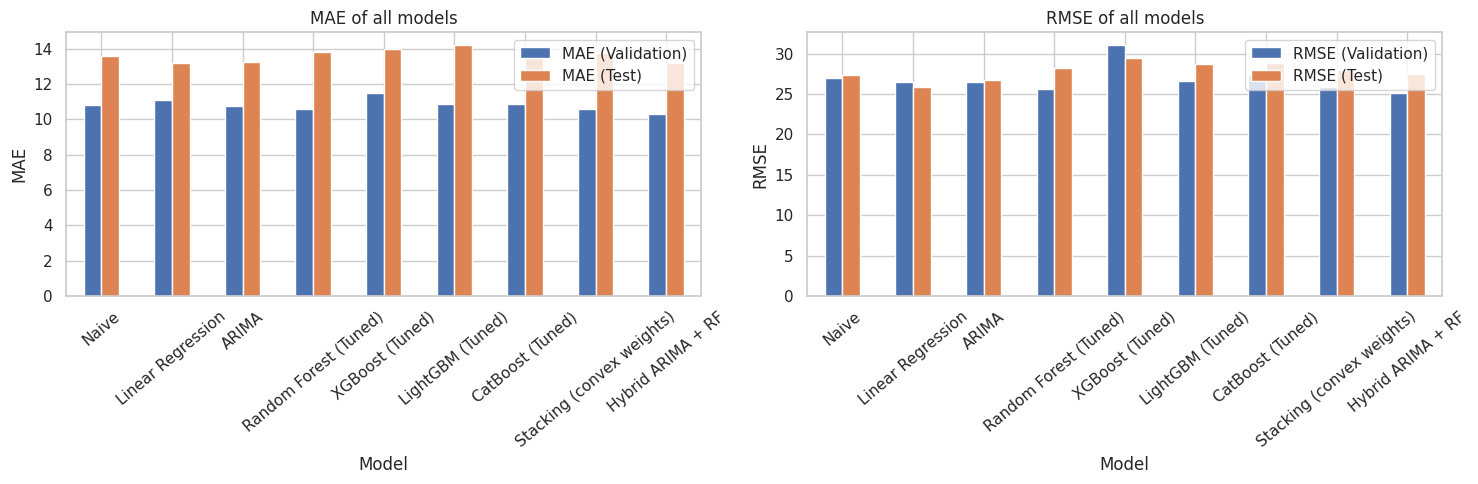

predictions: (4600, 15) | missing values: 0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

# ---------- 1. Final comparison of all models ----------
final_models = ["Naive", "Linear Regression", "ARIMA", "Random Forest (Tuned)", "XGBoost (Tuned)",
                "LightGBM (Tuned)", "CatBoost (Tuned)", "Stacking (convex weights)", "Hybrid ARIMA + RF"]
res = pd.DataFrame(results)
res = res[res["Model"].isin(final_models)]

table = res.pivot(index="Model", columns="Dataset", values=["MAE", "RMSE", "R2"])
table.columns = [f"{metric} ({dataset})" for metric, dataset in table.columns]
table = table.loc[final_models]

# Accuracy % = 100 * (1 - MAE / mean actual next-week cases)
table["Accuracy % (Validation)"] = 100 * (1 - table["MAE (Validation)"] / y_val.mean())
table["Accuracy % (Test)"]       = 100 * (1 - table["MAE (Test)"] / y_test.mean())

cols = ["MAE (Validation)", "MAE (Test)", "RMSE (Validation)", "RMSE (Test)",
        "R2 (Validation)", "R2 (Test)", "Accuracy % (Validation)", "Accuracy % (Test)"]
display(table[cols].sort_values("MAE (Test)").round(3))

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for a, metric in zip(ax, ["MAE", "RMSE"]):
    table[[f"{metric} (Validation)", f"{metric} (Test)"]].plot.bar(ax=a, rot=40)
    a.set_title(f"{metric} of all models"); a.set_ylabel(metric)
plt.tight_layout(); plt.show()

# ---------- 2. Files for the dashboard ----------
def pred_frame(frame, split, actual, preds):
    out = frame[["District", "Week_Start_Date"]].copy()
    out["Target_Week"] = out["Week_Start_Date"] + pd.Timedelta(days=7)
    out["Split"] = split
    out["Current_week_cases"] = frame["Number_of_Cases"].values
    out["Actual_next_week"] = np.asarray(actual)
    for name, p in preds.items():
        out[name] = np.asarray(p, dtype=float)
    return out

val_preds = {"Naive": val_df["Number_of_Cases"].values, "Linear Regression": lin_val_pred,
             "ARIMA": arima_val_pred, "Random Forest": rf_best_val_pred, "XGBoost": xgb_val_pred,
             "LightGBM": lgbm_val_pred, "CatBoost": cat_val_pred,
             "Stacking": stack2_val_pred, "Hybrid ARIMA + RF": hybrid_val_pred}
test_preds = {"Naive": test_df["Number_of_Cases"].values, "Linear Regression": lin_test_pred,
              "ARIMA": arima_test_pred, "Random Forest": rf_best_test_pred, "XGBoost": xgb_test_pred,
              "LightGBM": lgbm_test_pred, "CatBoost": cat_test_pred,
              "Stacking": stack2_test_pred, "Hybrid ARIMA + RF": hybrid_test_pred}

predictions = pd.concat([pred_frame(val_df, "Validation", y_val, val_preds),
                         pred_frame(test_df, "Test", y_test, test_preds)], ignore_index=True)

# training-period case levels per district (used later to define risk levels)
thresholds = (train_df.groupby("District")["target_next_week_cases"]
              .quantile([0.5, 0.8]).unstack().rename(columns={0.5: "p50", 0.8: "p80"}).reset_index())

predictions.to_csv("predictions.csv", index=False)
table[cols].round(3).reset_index().to_csv("model_comparison.csv", index=False)
thresholds.to_csv("risk_thresholds.csv", index=False)

print("predictions:", predictions.shape, "| missing values:", int(predictions.isna().sum().sum()))
files.download("predictions.csv"); files.download("model_comparison.csv"); files.download("risk_thresholds.csv")

In [ ]:
from google.colab import files

RAIN = "Total Precipitation (mm)"
TEMP = "Avg Max Temp (°C)"

def build_features(d):
    """Same feature construction as Section 8, without removing the last week."""
    f = d.sort_values(["District", "Week_Start_Date"]).reset_index(drop=True).copy()
    g = f.groupby("District")
    for lag in [1, 2, 4, 8, 12]:
        f[f"cases_lag{lag}"] = g["Number_of_Cases"].shift(lag)
    f["cases_roll4_mean"] = g["Number_of_Cases"].transform(lambda s: s.shift(1).rolling(4).mean())
    for lag in [2, 4, 6, 8, 10]:
        f[f"rain_lag{lag}"] = g[RAIN].shift(lag)
    for window in [4, 8, 12]:
        f[f"rain_sum{window}"] = g[RAIN].transform(lambda s: s.shift(1).rolling(window).sum())
    for lag in [4, 8]:
        f[f"maxtemp_lag{lag}"] = g[TEMP].shift(lag)
    f["Week_sin"] = np.sin(2 * np.pi * f["Week"] / 52)
    f["Week_cos"] = np.cos(2 * np.pi * f["Week"] / 52)
    f["District_code"] = f["District"].astype("category").cat.codes
    return f

all_feats = build_features(df)
last_week = all_feats["Week_Start_Date"].max()
latest = all_feats[all_feats["Week_Start_Date"] == last_week].reset_index(drop=True)
print("Last week in the data:", last_week.date(), "| forecast week:", (last_week + pd.Timedelta(days=7)).date())
print("Districts:", len(latest), "| missing feature values:", int(latest[feature_cols].isna().sum().sum()))

X_new = latest[feature_cols]

# ARIMA forecast for the next week (parameters estimated on the training period only)
arima_next = {}
for district, g in df.sort_values(["District", "Week_Start_Date"]).groupby("District"):
    y = g["Number_of_Cases"].values.astype(float)
    n_train = int((g["Week_Start_Date"] <= TRAIN_END).sum())
    fitted_model = ARIMA(y[:n_train], order=best_order).fit()
    arima_next[district] = float(np.clip(np.asarray(fitted_model.apply(y, refit=False).forecast(1))[0], 0, None))
arima_new = latest["District"].map(arima_next).values

X_new_h = X_new.copy(); X_new_h["arima_pred"] = arima_new

forecast_preds = {
    "Naive": latest["Number_of_Cases"].values,
    "ARIMA": arima_new,
    "Random Forest": rf_best.predict(X_new),
    "XGBoost": xgb_best.predict(X_new, iteration_range=(0, xgb_best.best_iteration + 1)),
    "LightGBM": lgbm_best.predict(X_new, num_iteration=lgbm_best.best_iteration_),
    "CatBoost": cat_best.predict(X_new),
}
forecast_preds["Stacking"] = np.column_stack([forecast_preds["Random Forest"], forecast_preds["XGBoost"],
                                              forecast_preds["LightGBM"], forecast_preds["CatBoost"]]) @ best_w
forecast_preds["Hybrid ARIMA + RF"] = np.clip(arima_new + rf_resid.predict(X_new_h[hybrid_features]), 0, None)

forecast = pd.DataFrame({"District": latest["District"], "Last_data_week": last_week,
                         "Forecast_week": last_week + pd.Timedelta(days=7),
                         "Current_week_cases": latest["Number_of_Cases"].values})
for name, p in forecast_preds.items():
    forecast[name] = np.clip(np.asarray(p, dtype=float), 0, None)

display(forecast.round(1).head(10))
forecast.to_csv("forecast_next_week.csv", index=False)
xgb_best.save_model("xgboost_model.json")
files.download("forecast_next_week.csv")
files.download("xgboost_model.json")

Last week in the data: 2024-07-15 | forecast week: 2024-07-22
Districts: 25 | missing feature values: 0


,District,Last_data_week,Forecast_week,Current_week_cases,Naive,ARIMA,Random Forest,XGBoost,LightGBM,CatBoost,Stacking,Hybrid ARIMA + RF
0,Ampara,2024-07-15,2024-07-22,18,18.0,18.0,15.4,16.4,15.9,14.4,15.0,17.7
1,Anuradhapura,2024-07-15,2024-07-22,10,10.0,11.0,11.2,9.3,9.0,7.5,9.7,10.2
2,Badulla,2024-07-15,2024-07-22,6,6.0,7.2,10.4,10.6,9.8,10.5,10.4,7.7
3,Batticaloa,2024-07-15,2024-07-22,9,9.0,10.1,12.5,11.7,10.8,10.4,11.6,10.0
4,Colombo,2024-07-15,2024-07-22,328,328.0,319.9,335.6,294.7,323.1,335.1,335.4,330.9
5,Galle,2024-07-15,2024-07-22,44,44.0,42.3,42.4,37.5,39.6,42.8,42.6,40.2
6,Gampaha,2024-07-15,2024-07-22,122,122.0,121.0,130.6,142.2,139.4,148.5,137.8,142.1
7,Hambantota,2024-07-15,2024-07-22,8,8.0,9.0,12.2,10.9,10.6,9.1,11.0,9.7
8,Jaffna,2024-07-15,2024-07-22,10,10.0,12.0,14.8,13.0,12.3,12.8,14.0,12.1
9,Kalutara,2024-07-15,2024-07-22,46,46.0,46.0,63.8,55.1,63.5,64.0,63.9,54.8


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Final Model Comparison

Accuracy % is calculated as 100 × (1 − MAE ÷ average actual cases), so it ranks the models in the same way as MAE. It is higher on the test set than on the validation set only because the average number of cases is higher in the test period (59.4 vs 38.0), not because the models are better there; the MAE is actually larger on the test set.

The Hybrid ARIMA + RF has the lowest MAE on both the validation set (10.32, accuracy 72.8%) and the test set (13.18, accuracy 77.8%). However, the differences between the models are small. On the test set the three best models (Hybrid 13.18, Linear Regression 13.20 and ARIMA 13.27) are within 1% of each other, and the test accuracy of all nine models lies between 76.1% and 77.8%. Linear Regression (25.87) and ARIMA (26.77) have a lower test RMSE than the Hybrid (27.48), so the Hybrid makes larger errors in the biggest outbreak weeks. The simple Naive Forecast (13.57) has a lower test MAE than the stacking model and all four tree-based models.

**Random Forest vs XGBoost:** The Random Forest is better than XGBoost on both sets (validation MAE 10.57 vs 11.47 and RMSE 25.62 vs 31.10; test MAE 13.82 vs 14.00 and RMSE 28.19 vs 29.43). The Random Forest was tuned over seven configurations and XGBoost over three, so the tuning effort was not identical.

Overall, none of the ensemble models clearly beat the simple baselines. This is consistent with the strong persistence of dengue cases (lag-1 autocorrelation 0.85) and with the feature importances, which show that the current and previous weeks' cases dominate the predictions, although this explanation was not tested directly.

## Predictor files for dashboard

In [ ]:

import os, json, shutil
from importlib.metadata import version
import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error

OUT = "predictor_files"
os.makedirs(OUT, exist_ok=True)
RAIN, TMAX, TMIN, WIND = "Total Precipitation (mm)", "Avg Max Temp (°C)", "Avg Min Temp (°C)", "Avg Wind Speed (km/h)"

#  1. District-week profile (median cases, mean weather for every week of the year, all years)
def make_profile(d):
    d = d.copy()
    d["WeekN"] = d["Week"].clip(upper=52)                      # week 53 is merged into week 52
    return (d.groupby(["District", "WeekN"])
            .agg(cases_median=("Number_of_Cases", "median"), rain_mean=(RAIN, "mean"), tmax_mean=(TMAX, "mean"),
                 tmin_mean=(TMIN, "mean"), wind_mean=(WIND, "mean"))
            .reset_index().rename(columns={"WeekN": "Week"}))

def profile_dict(p):
    return {(r.District, int(r.Week)): {"cases_median": float(r.cases_median), "rain_mean": float(r.rain_mean),
                                        "tmax_mean": float(r.tmax_mean), "tmin_mean": float(r.tmin_mean),
                                        "wind_mean": float(r.wind_mean)} for r in p.itertuples()}

make_profile(df).round(4).to_csv(f"{OUT}/district_week_profile.csv", index=False)

SRC_INPUT = "✍️ You entered"
SRC_CALC = "🧮 Calculated from your cases"
SRC_RAIN = "🌧️ District-week average × rainfall setting"
SRC_MED = "📊 District-week median"
SRC_MEAN = "📊 District-week average"
SRC_FIXED = "📅 Calculated from district and week"

def profile_value(prof, district, week, k, col):
    """Profile value for the week k weeks before `week` (negative k = after). Weeks wrap around a 52-week year;
    week 53 is treated as week 52."""
    w = (min(int(week), 52) - k - 1) % 52 + 1
    return float(prof[(district, w)][col])


def whatif_features(district, codes, prof, week, c0, c1, c2, c3, c4, rain_scale):
    """The 24 model features from five case counts, a rainfall setting and the district-week profile."""
    pv = lambda k, col: profile_value(prof, district, week, k, col)
    r = {k: rain_scale * pv(k, "rain_mean") for k in range(13)}
    feats = {
        "Number_of_Cases": float(c0), "cases_lag1": float(c1), "cases_lag2": float(c2), "cases_lag4": float(c4),
        "cases_lag8": pv(8, "cases_median"), "cases_lag12": pv(12, "cases_median"),
        "cases_roll4_mean": (c1 + c2 + c3 + c4) / 4.0,
        RAIN: r[0], TMAX: pv(0, "tmax_mean"), TMIN: pv(0, "tmin_mean"), WIND: pv(0, "wind_mean"),
        "rain_lag2": r[2], "rain_lag4": r[4], "rain_lag6": r[6], "rain_lag8": r[8], "rain_lag10": r[10],
        "rain_sum4": sum(r[k] for k in range(1, 5)), "rain_sum8": sum(r[k] for k in range(1, 9)),
        "rain_sum12": sum(r[k] for k in range(1, 13)),
        "maxtemp_lag4": pv(4, "tmax_mean"), "maxtemp_lag8": pv(8, "tmax_mean"),
        "Week_sin": float(np.sin(2 * np.pi * week / 52)), "Week_cos": float(np.cos(2 * np.pi * week / 52)),
        "District_code": codes[district],
    }
    sources = {"Number_of_Cases": SRC_INPUT, "cases_lag1": SRC_INPUT, "cases_lag2": SRC_INPUT, "cases_lag4": SRC_INPUT,
               "cases_lag8": SRC_MED, "cases_lag12": SRC_MED, "cases_roll4_mean": SRC_CALC,
               RAIN: SRC_RAIN, TMAX: SRC_MEAN, TMIN: SRC_MEAN, WIND: SRC_MEAN,
               "rain_lag2": SRC_RAIN, "rain_lag4": SRC_RAIN, "rain_lag6": SRC_RAIN, "rain_lag8": SRC_RAIN,
               "rain_lag10": SRC_RAIN, "rain_sum4": SRC_RAIN, "rain_sum8": SRC_RAIN, "rain_sum12": SRC_RAIN,
               "maxtemp_lag4": SRC_MEAN, "maxtemp_lag8": SRC_MEAN,
               "Week_sin": SRC_FIXED, "Week_cos": SRC_FIXED, "District_code": SRC_FIXED}
    return feats, sources

codes = {d: i for i, d in enumerate(sorted(df["District"].unique()))}
nb_codes = pd.concat([train_df, val_df, test_df]).groupby("District")["District_code"].first().astype(int).to_dict()
assert codes == nb_codes, "District codes of the app and of the notebook differ"

# ---------- 3. Models used by the page: Random Forest, Linear Regression and the members of the stacking
best_w = np.asarray(best_w, dtype=float)                       # convex stacking weights (RF, XGBoost, LightGBM, CatBoost)
stack_names = ["Random Forest", "XGBoost", "LightGBM", "CatBoost"]
stack_weights = {n: float(w) for n, w in zip(stack_names, best_w)}
needed = [n for n, w in stack_weights.items() if w > 1e-9]     # a member with weight 0 needs no file
print("Stacking weights:", {k: round(v, 3) for k, v in stack_weights.items()}, "| files needed for:", needed)

joblib.dump(rf_best, f"{OUT}/rf_model.joblib", compress=3)
if "XGBoost" in needed:
    xgb_best.save_model(f"{OUT}/xgboost_model.json")
if "LightGBM" in needed:
    lgbm_best.booster_.save_model(f"{OUT}/lightgbm_model.txt", num_iteration=lgbm_best.best_iteration_)
if "CatBoost" in needed:
    cat_best.save_model(f"{OUT}/catboost_model.cbm")

params = {
    "feature_cols": list(feature_cols),
    "linear": {"columns": list(X_train_lin.columns), "coef": [float(c) for c in lin_model.coef_],
               "intercept": float(lin_model.intercept_)},
    "stacking_weights": stack_weights,
    "xgb_n_trees": int(xgb_best.best_iteration) + 1,
}
with open(f"{OUT}/predictor_params.json", "w", encoding="utf-8") as fh:
    json.dump(params, fh)

# ---------- 4. Check that the saved files reproduce the notebook predictions (differences should be ~0)
lin_json = X_test_lin.values @ np.array(params["linear"]["coef"]) + params["linear"]["intercept"]
print("\nReload checks (largest difference from the notebook):")
print("  Random Forest    :", float(np.abs(joblib.load(f"{OUT}/rf_model.joblib").predict(X_test) - rf_best_test_pred).max()))
print("  Linear Regression:", float(np.abs(np.clip(lin_json, 0, None) - lin_test_pred).max()))
if "CatBoost" in needed:
    from catboost import CatBoostRegressor
    c = CatBoostRegressor(); c.load_model(f"{OUT}/catboost_model.cbm")
    print("  CatBoost         :", float(np.abs(c.predict(X_test) - cat_test_pred).max()))
if "XGBoost" in needed:
    import xgboost as xgb_lib
    bst = xgb_lib.Booster(); bst.load_model(f"{OUT}/xgboost_model.json")
    print("  XGBoost          :", float(np.abs(bst.predict(xgb_lib.DMatrix(X_test), iteration_range=(0, params["xgb_n_trees"])) - xgb_test_pred).max()))
if "LightGBM" in needed:
    import lightgbm as lgb_lib
    print("  LightGBM         :", float(np.abs(lgb_lib.Booster(model_file=f"{OUT}/lightgbm_model.txt").predict(X_test) - lgbm_test_pred).max()))
print("  Stacking         :", float(np.abs(np.clip(np.column_stack([rf_best_test_pred, xgb_test_pred, lgbm_test_pred, cat_test_pred]) @ best_w, 0, None) - stack2_test_pred).max()))

# ---------- 5. Backtest: test MAE with all 24 real features vs only the inputs of the page
# Inputs = real cases of this week and 1-4 weeks ago, rainfall 100% of normal. Everything else comes from the
# district-week profile of the TRAINING years only (no test data used).
def predict3(X, districts):
    lin_in = X.copy()
    lin_in["District"] = list(districts)
    lin = lin_model.predict(make_linear_matrix(lin_in).reindex(columns=X_train_lin.columns, fill_value=0))
    base = np.column_stack([rf_best.predict(X),
                            xgb_best.predict(X, iteration_range=(0, xgb_best.best_iteration + 1)),
                            lgbm_best.predict(X, num_iteration=lgbm_best.best_iteration_),
                            cat_best.predict(X)])
    return {"Random Forest": np.clip(rf_best.predict(X), 0, None), "Linear Regression": np.clip(lin, 0, None),
            "Stacking": np.clip(base @ best_w, 0, None)}

tmp = df.sort_values(["District", "Week_Start_Date"]).copy()
tmp["cases_lag3"] = tmp.groupby("District")["Number_of_Cases"].shift(3)
tb = test_df.merge(tmp[["District", "Week_Start_Date", "cases_lag3"]], on=["District", "Week_Start_Date"], how="left")
prof_train = profile_dict(make_profile(df[df["Week_Start_Date"] < "2021-01-01"]))
rows = [whatif_features(r.District, codes, prof_train, r.Week, r.Number_of_Cases, r.cases_lag1, r.cases_lag2,
                        r.cases_lag3, r.cases_lag4, 1.0)[0] for r in tb.itertuples()]
X_wi = pd.DataFrame(rows)[list(feature_cols)]

y_true = np.asarray(y_test, dtype=float)
full = predict3(test_df[feature_cols], test_df["District"])
limited = predict3(X_wi, tb["District"])
backtest = pd.DataFrame([{"Model": m, "MAE_full": mean_absolute_error(y_true, full[m]),
                          "MAE_whatif": mean_absolute_error(y_true, limited[m])} for m in full])
backtest.round(4).to_csv(f"{OUT}/whatif_backtest.csv", index=False)
print("\nBacktest (test period, MAE):")
print(backtest.round(3).to_string(index=False))
print("Naive MAE:", round(mean_absolute_error(y_true, test_df["Number_of_Cases"]), 3))

# ---------- 6. File sizes (GitHub allows up to 100 MB per file) and the lines for requirements.txt
print("\nFile sizes:")
for name in sorted(os.listdir(OUT)):
    mb = os.path.getsize(f"{OUT}/{name}") / 1e6
    print(f"  {name:28s}{mb:8.1f} MB", "  <-- too big for GitHub" if mb > 95 else "")
print("\nAdd these lines to requirements.txt of the app:")
extra = {"XGBoost": "xgboost", "LightGBM": "lightgbm", "CatBoost": "catboost"}
for pkg in ["scikit-learn", "joblib"] + [extra[n] for n in needed if n in extra]:
    print(f"{pkg}=={version(pkg)}")

shutil.make_archive("predictor_files", "zip", OUT)
try:
    from google.colab import files
    files.download("predictor_files.zip")
except ImportError:
    print("\nSaved in the folder:", os.path.abspath(OUT))

Stacking weights: {'Random Forest': 0.6, 'XGBoost': 0.0, 'LightGBM': 0.0, 'CatBoost': 0.4} | files needed for: ['Random Forest', 'CatBoost']

Reload checks (largest difference from the notebook):
  Random Forest    : 1.1368683772161603e-13
  Linear Regression: 0.0
  CatBoost         : 0.0
  Stacking         : 0.0

Backtest (test period, MAE):
            Model  MAE_full  MAE_whatif
    Random Forest    13.821      13.564
Linear Regression    13.200      13.043
         Stacking    13.761      13.379
Naive MAE: 13.571

File sizes:
  catboost_model.cbm               0.1 MB 
  district_week_profile.csv        0.1 MB 
  predictor_params.json            0.0 MB 
  rf_model.joblib                 22.2 MB 
  whatif_backtest.csv              0.0 MB 

Add these lines to requirements.txt of the app:
scikit-learn==1.6.1
joblib==1.6.0
catboost==1.2.10


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Training time CSV file for dashboard


In [ ]:
import time
from google.colab import files

# Time the Linear Regression fit (it was not timed before)
start = time.time()
LinearRegression().fit(X_train_lin, y_train)
lr_time = time.time() - start

# Times taken from the notebook outputs (seconds)
t_rf, t_xgb, t_lgb, t_cat = 81.7, 2.2, 8.3, 5.2      # best configurations
t_oof = 212.0                                          # stacking: 5 chronological folds
t_arima, t_resid_rf = 4.8, 65.5                        # hybrid: ARIMA + residual Random Forest

training_time = pd.DataFrame({
    "Model": ["Naive", "Linear Regression", "ARIMA", "Random Forest", "XGBoost", "LightGBM",
              "CatBoost", "Stacking", "Hybrid ARIMA + RF"],
    "Training_time_sec": [0.0, round(lr_time, 2), t_arima, t_rf, t_xgb, t_lgb, t_cat,
                          round(t_rf + t_xgb + t_lgb + t_cat + t_oof, 1),   # base models + 5 folds
                          round(t_arima + t_resid_rf, 1)],
})
display(training_time)
training_time.to_csv("training_time.csv", index=False)
files.download("training_time.csv")

,Model,Training_time_sec
0,Naive,0.00
1,Linear Regression,0.07
2,ARIMA,4.80
3,Random Forest,81.70
4,XGBoost,2.20
5,LightGBM,8.30
6,CatBoost,5.20
7,Stacking,309.40
8,Hybrid ARIMA + RF,70.30


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>